<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/HybridQNN_AdversarialNoise_Akter2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN versus NN under adversarial noise on ClaMP malware data: Akter et al. (2023) step by step

This notebook re-implements, runs and checks the method of

> Mst Shapna Akter, Hossain Shahriar, Iysa Iqbal, MD Hossain, M. A. Karim, Victor Clincy and Razvan Voicu,
> "Exploring the Vulnerabilities of Machine Learning and Quantum Machine Learning to Adversarial Attacks using a Malware
> Dataset: A Comparative Analysis", *2023 IEEE International Conference on Software Services Engineering (SSE)*, 2023.
> https://doi.org/10.1109/SSE60056.2023.00037

The paper publishes no code. Everything below is written from its method section (Section III, Algorithm 1, Section IV) and
from the figures of the PDF, with the software stack it names (PennyLane, TensorFlow / Keras, scikit-learn).

**What the notebook does.** It downloads the ClaMP malware dataset (5,210 Windows PE files, 69 header fields, 52 % malware),
applies the paper's preprocessing (shuffle, one-hot encoding of the packer type to 108 features, standardisation, PCA to 16
components), and cuts the file the way Section III describes: 80 % for training, validation and testing (60 / 20 / 20) and 20 %
kept for "fine-tuning" with perturbed data. It trains a classical neural network (Keras) and a quantum neural network
(the TensorFlow-Quantum tutorial circuit that the paper's Section IV describes, rebuilt in PennyLane, with an exact closed
form that is verified against the 17-qubit simulation) for the paper's 100 epochs and with its hinge loss. Then it attacks both
models the way the paper does, by adding scaled Gaussian noise (Algorithm 1), once at test time and once through the
fine-tuning set, and reports accuracy, precision, recall, F1, confusion matrices, ROC and precision-recall curves before and
after the attack (the paper's Tables 1 and 2 and Figures 2 to 7). Because the paper's abstract also claims that adversarial
samples "crafted for one model type can impair the performance of the other", the notebook adds a transfer study with
gradient-crafted attacks (FGSM on the NN, a budgeted bit-flip attack on the QNN, FGSM on the angle-encoded circuit of the
paper's Figure 1) and four classical baselines. The last section puts every number of the paper next to ours with a verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, do so and run all cells again. Nothing needs a GPU or a quantum account.

**Runtime.** With `FAST_MODE = True` (one seed, 3 noise draws, a 3-epoch run of the Figure-1 circuit) the notebook takes about
5 minutes on a laptop CPU (expect 8-12 minutes on a Colab CPU). With `FAST_MODE = False` (three seeds, 10 noise draws,
20 epochs for the Figure-1 circuit) it took 22 minutes on the validation machine (a shared laptop CPU). The committed
notebook contains the outputs of the run named in the configuration cell.

**What you get at the end.** The paper's Tables 1 and 2 re-computed (with mean +- std over seeds), confusion matrices, ROC and
precision-recall curves for clean and perturbed data, an epsilon sweep and a perturbed-fraction sweep, a fine-tuning study, a
cross-model transfer matrix, a verdict for each number and claim of the paper, a critical reading, and five exercises.

## The paper in one page

**Problem.** Decide from the fields of a Windows executable's PE header whether the file is malware (class 1) or benign
(class 0), and compare how a classical neural network (NN) and a quantum neural network (QNN) degrade when the data is
perturbed by an adversary.

**Decision.** Binary classification of a 16-dimensional PCA projection of the ClaMP features. A positive QNN read-out (hinge
labels +1 / -1) means malware.

**Method (Sections III and IV).**
1. *Preprocessing*: shuffle, reset the index, drop unnecessary columns, convert the categorical column to numbers, normalise
   ("108 dimensions"), PCA to the first 16 components "because of the qubit limit of the simulator".
2. *Split* (Sections III and IV-B): 80 % of the 5,210 rows for training / validation / testing (60 / 20 / 20 of that 80 %),
   the remaining 20 % for "fine-tuning the model", to which "perturbed data" is added.
3. *NN*: a TensorFlow / Keras network applied directly to the 16 components.
4. *QNN*: classical data encoded as circuits, converted to TensorFlow Quantum, "a two-layer model circuit with a data circuit
   size that matched the input" wrapped in a TFQ-Keras model, hinge loss, labels converted to -1 / +1, 100 epochs (Figure 1
   draws a generic 4-qubit circuit with RX input encoding, RY + CNOT-chain layers and a measurement of every qubit).
5. *Attack* (Algorithm 1): `perturbed = data + epsilon * np.random.randn(*data.shape)`; "random noise to a small portion of
   the dataset". The abstract adds that "adversarial samples crafted for one model type can impair the performance of the other".
6. *Metrics*: accuracy, precision, recall, F1 (Tables 1 and 2), confusion matrices (Figures 2 and 3), ROC (Figures 4 and 5),
   precision-recall curves (Figures 6 and 7).

**Data.** ClaMP (Kumar, Kuppusamy and Aghila, 2019): PE-header features of 2,722 malware files (VirusShare) and 2,488 benign
Windows files; the *Integrated* version has raw, derived and expanded features.

**Claims.**

| Claim | Paper's evidence |
|---|---|
| Before the attack the QNN is "marginally better" than the NN | Table 1: NN acc 0.54, P 1.00, R 0.57, F1 0.65; QNN acc 0.57, P 0.92, R 0.57, F1 0.65 |
| After the attack the QNN's accuracy drops more than the NN's, but its recall rises | Table 2: NN acc 0.52, P 0.27, R 0.52, F1 0.36; QNN acc 0.45, P 0.47, R 0.90, F1 0.62 |
| The QNN keeps a higher F1 after the attack ("greater resilience") | Table 2 and Section V |
| ROC AUC falls for the QNN (0.61 to 0.46), the NN is at 0.50 both times | Figures 4 and 5 |
| Precision-recall AUC: QNN 0.79 to 0.75, NN 0.78 to 0.71 | Figures 6 and 7 |
| Both model types are vulnerable and adversarial samples transfer between them | Abstract and Section V |

## What follows the paper and what had to be chosen

The paper fixes the dataset, 16 components, the 60 / 20 / 20 + 20 % split, the noise rule (Algorithm 1), the loss, the labels,
the optimiser and 100 epochs. It does not give epsilon, the noise scale, the fraction perturbed, the NN architecture, the
learning rates, the batch size, which columns were dropped, how a continuous component becomes "a qubit value", how the
fine-tuning is done, or a seed. Where the paper is silent this notebook makes a choice and says so in the code (`# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | ClaMP_Integrated, 5,210 rows (also written 5,184) | Same file from the authors' GitHub repository (5,210 rows, 69 features + label), downloaded inside the notebook |
| Encoding / scaling / PCA | categorical to numbers ("108 dimensions"), normalisation, PCA 16 | One-hot of the 40 packer types (108 features), `StandardScaler`, `PCA(16)`, all fitted on the training split only |
| Split | 80 % (60 / 20 / 20) + 20 % fine-tuning | Stratified: 20 % fine-tuning set (1,042 rows), then 60 / 20 / 20 of the other 80 % (2,500 / 834 / 834 rows) |
| NN | TensorFlow / Keras, no architecture | Keras 16-16-1 (ReLU, sigmoid), binary cross-entropy, Adam 0.001, batch 32, 100 epochs, on the 16 PCs (`# CHOICE`) |
| QNN | TFQ model circuit, hinge loss, 100 epochs | The TFQ-tutorial circuit (X-encoded data qubits, XX layer, ZZ layer into a readout qubit), 32 angles, Adam 0.01, batch 32, 100 epochs; closed form + 17-qubit PennyLane simulation (`# CHOICE`) |
| "Qubit value" | all features "converted into a qubit value" | Data qubit *q* is \|1> when principal component *q* > 0 (`# CHOICE`) |
| Figure-1 circuit | 4-qubit sketch: RX(psi) input, RY(theta) + CNOT chain, measure all | Added as a second QNN: 8 qubits, RX angle encoding of PCs 1-8 scaled to [0, pi] (1st-99th percentile), 2 layers, 4 x mean of the 8 Z read-outs + trainable bias, hinge loss; reduced epoch budget (`# CHOICE`) |
| Noise | `data + eps * randn`, eps not given, "small portion" | Noise on the 16 components, scaled by each component's training standard deviation (so epsilon is in units of spread), eps = 0.5, all test rows (`# CHOICE`); sweeps over eps and over the perturbed fraction |
| Where the noise enters | "added to the 20 % fine-tuning dataset"; confusion matrices suggest test-time noise | Both: test-time perturbation (main, Tables 2) and fine-tuning on a half-perturbed fine-tuning set (Section 9) |
| Transfer claim | stated, never tested | Gradient-crafted FGSM on the NN and the Figure-1 circuit, budgeted bit-flip attack on the QNN, victims: all models |
| Baselines | none | RandomForest and SVC (rbf) on the 16 PCs and on the 16 bits the QNN sees |
| Repetitions | one run | 3 seeds (1 in `FAST_MODE`) x 10 noise draws (3), mean +- std |
| AUC definition | not stated | Both the score-based ROC / PR AUC and the "hard-label" AUC that the paper's figures turn out to use (Section 10) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and TensorFlow.
# The pip lines run on Colab (or wherever the package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("tensorflow") is None:
    %pip install -q "tensorflow-cpu==2.21.0"
    print("TensorFlow installed.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: one seed, 3 noise draws, 3-epoch Figure-1 circuit (about 5 min). False: 3 seeds, 10 draws, 20 epochs (about 22 min).

SEED       = 42             # CHOICE: the paper gives no seed
N_QUBITS   = 16             # paper: 16 principal components -> 16 data qubits (+ 1 readout qubit, as in the TFQ tutorial)
FT_SIZE    = 0.2            # paper: 20 % of the 5,210 rows kept for fine-tuning
HOLDOUT    = 0.4            # paper: 60 % training, 20 % validation, 20 % test of the other 80 % (validation + test = 40 %)

EPOCHS     = 100            # paper: "we trained the QNN for 100 epochs" (the NN gets the same budget)
BATCH_SIZE = 32             # CHOICE: mini-batch size (TFQ tutorial default)
LR_QNN     = 0.01           # CHOICE: Adam step size for the QNN angles (paper: Adam optimiser mentioned, no rate)
LR_NN      = 0.001          # CHOICE: Keras Adam default
HIDDEN     = 16             # CHOICE: hidden units of the Keras NN (paper gives no architecture)
BIT_THRESHOLD = 0.0         # CHOICE: data qubit q is |1> when principal component q > 0 (components are centred on the training split)

# Algorithm 1 (random noise) and the crafted attacks
EPS        = 0.5            # CHOICE: noise std in units of each component's training std (paper: epsilon not given)
PERTURB_FRACTION = 1.0      # CHOICE: share of test rows perturbed (paper: "a small portion of the dataset"; swept in Section 8)
NOISE_DRAWS = 3 if FAST_MODE else 10          # independent noise matrices per evaluation (a single draw is a random event)
EPS_SWEEP  = [0.0, 0.25, 0.5, 1.0, 2.0] if FAST_MODE else [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0]
FRACTION_SWEEP = [0.1, 0.25, 0.5, 1.0]
SEEDS      = [SEED] if FAST_MODE else [SEED, SEED + 1, SEED + 2]    # seed changes the split, PCA, initialisation, batch order and noise

# Fine-tuning study (Section 9)
FT_EPOCHS  = 10 if FAST_MODE else 20          # CHOICE: epochs of fine-tuning on the 20 % set (paper: not stated)
FT_PERTURBED_SHARE = 0.5    # CHOICE: share of the fine-tuning rows that receive Algorithm 1 noise ("mixture of clean and perturbed data")

# Second QNN: the generic circuit of the paper's Figure 1 (RX input encoding, RY + CNOT-chain layers)
FIG1_QUBITS, FIG1_LAYERS = 8, 2               # CHOICE: 8 qubits (16 qubits are too slow to train with a state-vector simulator here)
FIG1_EPOCHS = 3 if FAST_MODE else 20          # CHOICE: reduced budget; about 9 s per epoch on a laptop CPU
FIG1_BATCH, FIG1_LR = 64, 0.05                # CHOICE
FIG1_READOUT_SCALE = 4.0                      # CHOICE: output = 4 x mean(Z) + trainable bias (without it two of three seeds stayed at the majority class)

SIM_CHECK_ROWS = 8          # rows on which the closed form is checked against the 17-qubit simulator (outputs and gradients)

DATA_DIR   = "data"         # where the CSV is cached (relative to the working directory)
DATA_FILE  = "ClaMP_Integrated-5184.csv"
DATA_URLS  = ["https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv",
              "https://github.com/urwithajit9/ClaMP/raw/master/dataset/ClaMP_Integrated-5184.csv",
              "https://raw.githubusercontent.com/urwithajit9/ClaMP/main/dataset/ClaMP_Integrated-5184.csv"]
DATA_SOURCE = "download"    # "download" (default) or "upload": put the CSV into DATA_DIR yourself
IBM_TOKEN  = ""             # not used: every circuit is simulated exactly

In [3]:
import os, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)
from scipy.stats import spearmanr

import tensorflow as tf
from tensorflow import keras
import pennylane as qml
from pennylane import numpy as pnp          # autograd-backed NumPy: arrays with requires_grad=True carry a gradient

np.random.seed(SEED)                        # seeds everywhere: NumPy, our generators, scikit-learn random_state, TensorFlow below
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

import sklearn, scipy
print("pennylane", qml.version(), "| tensorflow", tf.__version__, "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| eps:", EPS, "| noise draws:", NOISE_DRAWS, "| epochs:", EPOCHS)

pennylane 0.45.1 | tensorflow 2.21.0 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | seeds: [42, 43, 44] | eps: 0.5 | noise draws: 10 | epochs: 100


## 1. The ClaMP malware dataset

ClaMP ("Classification of Malware with PE headers", Kumar, Kuppusamy and Aghila, *J. King Saud Univ. CIS* 31(2), 2019) describes
each Windows executable by fields of its PE header: the DOS header (`e_cblp`, `e_lfanew`, ...), the file header
(`NumberOfSections`, 15 characteristic flags `FH_char*`), the optional header (`SizeOfCode`, `AddressOfEntryPoint`,
`ImageBase`, `CheckSum`, 11 DLL-characteristic flags `OH_DLLchar*`, ...) and derived features (suspicious section
counts, packer presence and type, section entropies, file size and entropy). The label `class` is 1 for malware (collected from
VirusShare) and 0 for benign files (Windows system files and free software). The paper uses the *Integrated* file.

The cell below downloads it from the authors' public GitHub repository (several mirrors of the same raw URL are tried) and
caches it in `DATA_DIR`; set `DATA_SOURCE = "upload"` and copy the CSV there yourself if the download is blocked. The paper's
first steps, shuffling and resetting the index, are applied right away.

In [4]:
CSV_PATH = os.path.join(DATA_DIR, DATA_FILE)

def fetch_clamp(path):
    if os.path.exists(path):
        print("using cached", path)
        return pd.read_csv(path)
    if DATA_SOURCE == "upload":
        raise FileNotFoundError(f"DATA_SOURCE='upload' but {path} is missing")
    import requests
    last = None
    for url in DATA_URLS:                                   # try each mirror in turn
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            with open(path, "wb") as f:
                f.write(r.content)
            print("downloaded", url)
            return pd.read_csv(path)
        except Exception as e:
            last = e; print("failed:", url, "->", type(e).__name__)
    raise RuntimeError(f"could not download ClaMP: {last}")

t0 = time.time()
df_raw = fetch_clamp(CSV_PATH)
df = df_raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)      # paper: shuffle, then reset the index
print(f"loaded in {time.time()-t0:.1f} s: {df.shape[0]:,} rows x {df.shape[1]} columns  (paper: 5,210 rows)")
print("missing values:", int(df.isnull().sum().sum()))
FEATURES = [c for c in df.columns if c != "class"]
NUMERIC  = [c for c in FEATURES if c != "packer_type"]
print(f"{len(FEATURES)} feature columns = {len(NUMERIC)} numeric + packer_type ({df['packer_type'].nunique()} packer types); after one-hot "
      f"encoding: {len(NUMERIC) + df['packer_type'].nunique()} features (+ label)   (paper: '108 dimensions')")
df.head(3)

using cached data\ClaMP_Integrated-5184.csv
loaded in 0.2 s: 5,210 rows x 70 columns  (paper: 5,210 rows)
missing values: 0
69 feature columns = 68 numeric + packer_type (40 packer types); after one-hot encoding: 108 features (+ label)   (paper: '108 dimensions')


,e_cblp,e_cp,e_cparhdr,e_maxalloc,e_sp,e_lfanew,NumberOfSections,CreationYear,FH_char0,FH_char1,FH_char2,FH_char3,FH_char4,FH_char5,FH_char6,FH_char7,FH_char8,FH_char9,FH_char10,FH_char11,...,OH_DLLchar6,OH_DLLchar7,OH_DLLchar8,OH_DLLchar9,OH_DLLchar10,SizeOfStackReserve,SizeOfStackCommit,SizeOfHeapReserve,SizeOfHeapCommit,LoaderFlags,sus_sections,non_sus_sections,packer,packer_type,E_text,E_data,filesize,E_file,fileinfo,class
0,144,3,4,65535,184,224,7,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1048576,4096,1048576,4096,1,4,3,0,NoPacker,6.036959,1.454411,149504,7.587887,1,1
1,144,3,4,65535,184,224,5,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,262144,8192,1048576,4096,1,1,4,0,NoPacker,6.385794,4.203509,488448,6.120830,1,0
2,144,3,4,65535,184,232,4,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,262144,8192,1048576,4096,1,1,3,0,NoPacker,6.300261,4.488365,208944,6.313596,1,0


## 2. Preprocessing and the paper's split: 60 / 20 / 20 plus a 20 % fine-tuning set

The paper's pipeline is: one-hot encode the packer type, standardise, reduce to 16 principal components. The split of
Section III is: 20 % of the 5,210 rows are kept for fine-tuning, the other 80 % are divided 60 / 20 / 20 into training,
validation and test rows. Every transform (one-hot encoder, scaler, PCA) is fitted on the 2,500 training rows only and then
applied to the validation, test and fine-tuning rows. `make_split(seed)` returns everything one experiment needs; the seed
changes which rows land in which split, the PCA, and every random draw that follows.

The one-hot encoder fitted on the 2,500 training rows meets 28 of the 40 packer types (rare packers that occur only in the other splits are unseen and encoded as all zeros), so the model input has 96 columns instead of the paper's 108; fitting on all rows would give 108 but would let the test rows influence the encoder.

One more quantity is needed later: the training standard deviation of every principal component. The noise of Algorithm 1 is
scaled by it, so that `EPS = 0.5` means "noise with half the spread of that component" instead of an absolute number that
would mean something different for the first component (std about 2.6) and for the sixteenth (about 1.1).

In [5]:
def make_split(seed):
    '''One experiment's data: fine-tuning set (20 %), then 60/20/20 train/val/test of the rest; transforms fitted on train only.'''
    main_df, ft_df = train_test_split(df, test_size=FT_SIZE, stratify=df["class"], random_state=seed)        # paper: 20 % fine-tuning
    tr, rest = train_test_split(main_df, test_size=HOLDOUT, stratify=main_df["class"], random_state=seed)    # paper: 60 % train
    va, te = train_test_split(rest, test_size=0.5, stratify=rest["class"], random_state=seed)                # 20 % val / 20 % test
    encode = ColumnTransformer([("packer", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["packer_type"]),
                                ("num", "passthrough", NUMERIC)])
    pipe = Pipeline([("encode", encode), ("scale", StandardScaler()),
                     ("pca", PCA(n_components=N_QUBITS, random_state=seed))]).fit(tr[FEATURES])     # fitted on training rows only
    D = dict(seed=seed, pipe=pipe, pca=pipe["pca"], n_encoded=pipe["encode"].transform(tr[FEATURES]).shape[1])
    for name, part in [("train", tr), ("val", va), ("test", te), ("ft", ft_df)]:
        D["X_" + name] = pipe.transform(part[FEATURES])
        D["y_" + name] = part["class"].values.astype(int)
        D["bits_" + name] = (D["X_" + name] > BIT_THRESHOLD).astype(float)       # CHOICE: the 16 bits the QNN sees
    D["std"] = D["X_train"].std(axis=0)                                          # scale of the noise (units of spread)
    return D

t0 = time.time()
D = make_split(SEED)
print(f"split + preprocessing: {time.time()-t0:.1f} s; {D['n_encoded']} encoded columns -> 16 principal components "
      f"(explained variance {D['pca'].explained_variance_ratio_.sum():.3f})")
print(pd.DataFrame({"split": ["train", "validation", "test", "fine-tuning"],
                    "rows": [len(D["y_" + k]) for k in ("train", "val", "test", "ft")],
                    "malware share": [round(float(D["y_" + k].mean()), 3) for k in ("train", "val", "test", "ft")]}).to_string(index=False))
print("training std of the 16 components:", np.round(D["std"], 2))

split + preprocessing: 0.4 s; 96 encoded columns -> 16 principal components (explained variance 0.480)
      split  rows  malware share
      train  2500          0.522
 validation   834          0.523
       test   834          0.523
fine-tuning  1042          0.522
training std of the 16 components: [2.63 1.92 1.84 1.73 1.69 1.67 1.61 1.52 1.45 1.44 1.37 1.35 1.32 1.29
 1.26 1.17]


## Dataset Exploration and Visualisation

Before any model is trained, a look at the real data: the shape, the feature names and the two original label values with their
counts, the class distribution of the whole file and of every split, and two-dimensional scatter plots of real files coloured by
their ground-truth label (a handful of extreme files lie outside the axes of the first two plots; they are still in the data). The first scatter shows the raw PCA coordinates (fitted on the training split); the second the
bit view that the paper-style QNN actually receives (a file's data qubit is |1> when the component is above zero, so the
two axes cut the plane into four quadrants); the third the same two components scaled to [0, pi] (between the 1st and 99th training percentile), which is the angle
encoding of the Figure-1 circuit used later; the last shows what Algorithm 1 does to the test files. ClaMP only has the two
labels benign / malware (no attack-family label), so the colouring is binary.

dataset shape (rows, columns): (5210, 70)
features (69):
e_cblp, e_cp, e_cparhdr, e_maxalloc, e_sp, e_lfanew, NumberOfSections, CreationYear, FH_char0, FH_char1, FH_char2, FH_char3, FH_char4, FH_char5, FH_char6, FH_char7, FH_char8, FH_char9, FH_char10, FH_char11 ... non_sus_sections, packer, packer_type, E_text, E_data, filesize, E_file, fileinfo
original label column 'class' values: [0, 1] (1 = malware, 0 = benign)
class counts: {'benign (0)': 2488, 'malware (1)': 2722} -> malware share 52.2%
packer types (top 8): {'NoPacker': 4395, 'UPXv20MarkusLaszloReiser': 231, 'Armadillov171': 154, 'Armadillov1xxv2xx': 110, 'NETDLLMicrosoft': 93, 'NETexecutableMicrosoft': 90, 'BobSoftMiniDelphiBoBBobSoft': 25, 'UPXV200V290MarkusOberhumerLaszloMolnarJohnReiser': 14}


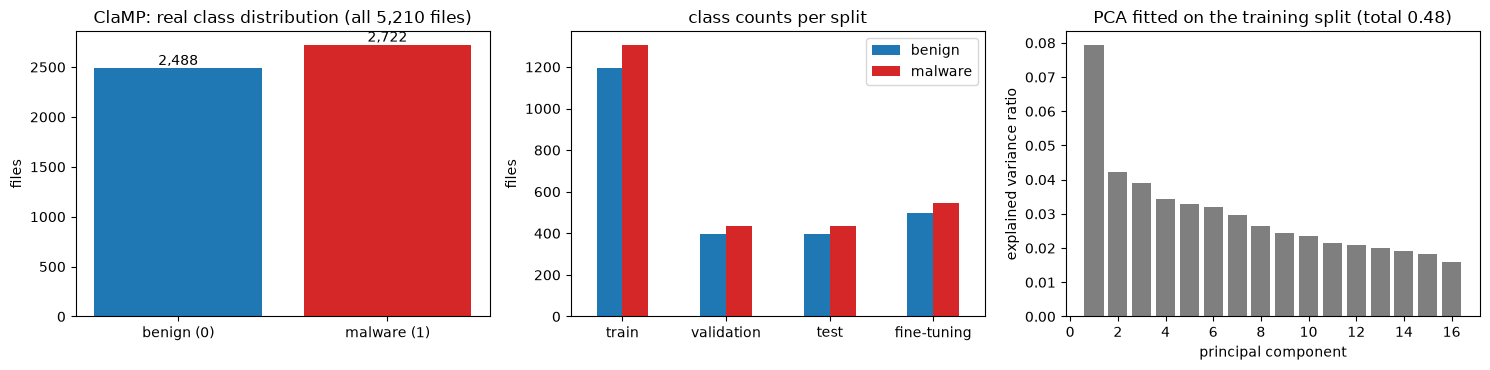

In [6]:
print("dataset shape (rows, columns):", df.shape)
print(f"features ({len(FEATURES)}):")
print(", ".join(FEATURES[:20]), "...", ", ".join(FEATURES[-8:]))
print("original label column 'class' values:", sorted(df["class"].unique().tolist()), "(1 = malware, 0 = benign)")
counts = df["class"].value_counts().sort_index()
print("class counts:", {"benign (0)": int(counts[0]), "malware (1)": int(counts[1])}, f"-> malware share {counts[1] / len(df):.1%}")
print("packer types (top 8):", df["packer_type"].value_counts().head(8).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(["benign (0)", "malware (1)"], [counts[0], counts[1]], color=["tab:blue", "tab:red"])
for i, v in enumerate([counts[0], counts[1]]):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("ClaMP: real class distribution (all 5,210 files)"); axes[0].set_ylabel("files")
split_counts = pd.DataFrame({k: np.bincount(D["y_" + s], minlength=2) for k, s in
                             [("train", "train"), ("validation", "val"), ("test", "test"), ("fine-tuning", "ft")]}, index=["benign", "malware"]).T
split_counts.plot.bar(ax=axes[1], color=["tab:blue", "tab:red"], rot=0); axes[1].set_title("class counts per split"); axes[1].set_ylabel("files")
axes[2].bar(range(1, 17), D["pca"].explained_variance_ratio_, color="tab:gray")
axes[2].set_xlabel("principal component"); axes[2].set_ylabel("explained variance ratio")
axes[2].set_title(f"PCA fitted on the training split (total {D['pca'].explained_variance_ratio_.sum():.2f})")
plt.tight_layout(); plt.show()

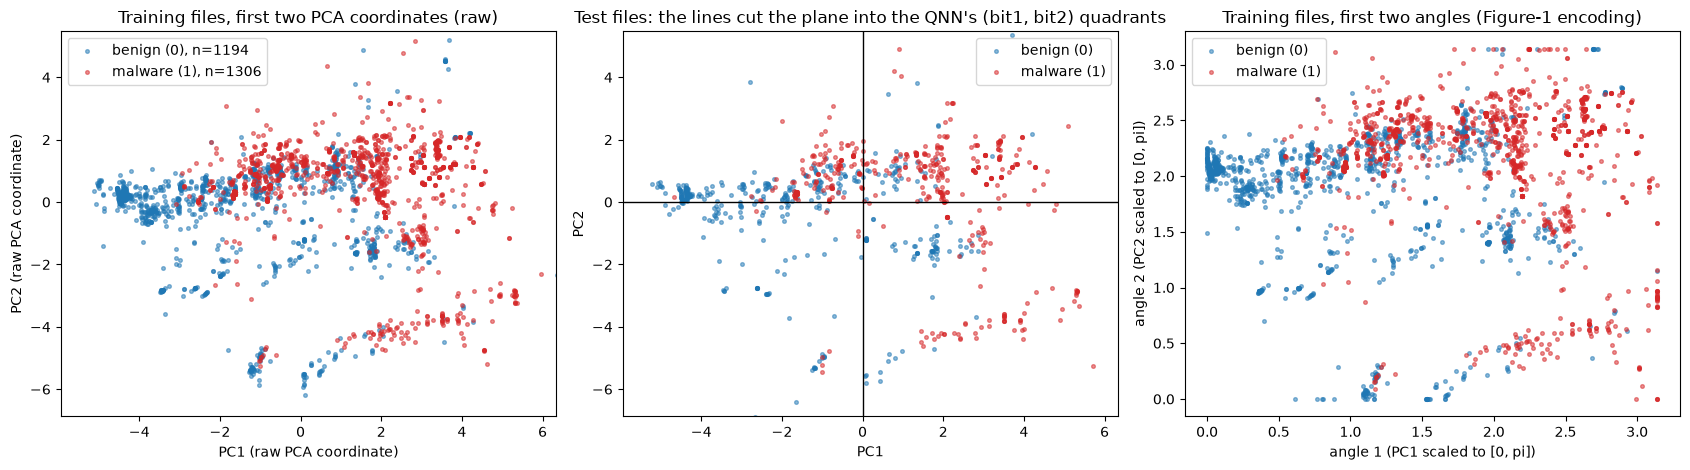

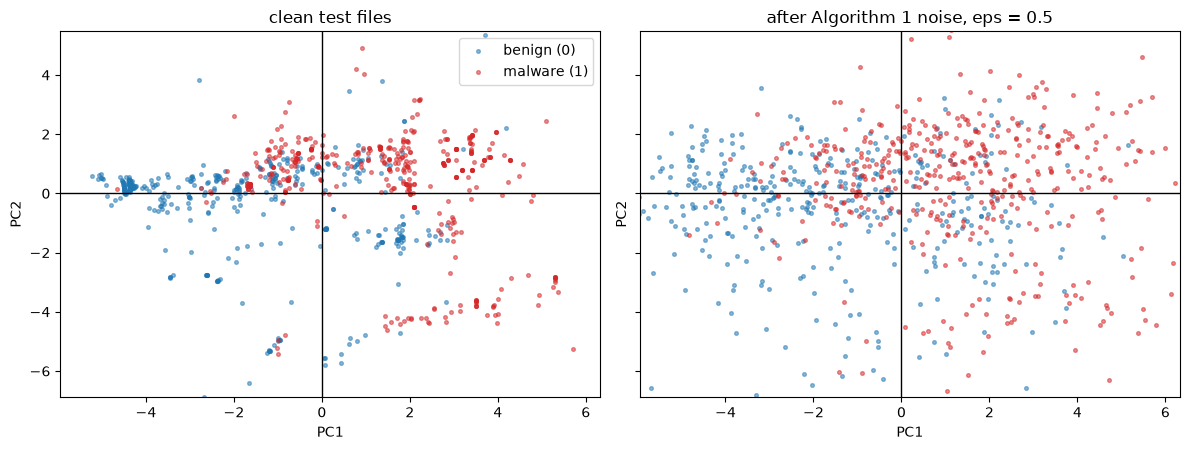

at eps = 0.5 Algorithm 1 flips 22.6% of the 16 bits the QNN reads (random flips, no knowledge of the model).


In [7]:
CLS = [(0, "tab:blue", "benign (0)"), (1, "tab:red", "malware (1)")]
lo, hi = np.percentile(D["X_train"][:, :2], 0.5, axis=0), np.percentile(D["X_train"][:, :2], 99.5, axis=0)   # a few extreme files are cut off the plot (still used by the models)
marg = 0.1 * (hi - lo); XL, YL = (lo[0] - marg[0], hi[0] + marg[0]), (lo[1] - marg[1], hi[1] + marg[1])
class AngleScaler:
    '''Maps principal components to angles in [0, pi]: linear between the 1st and 99th training percentile, clipped outside.
    # CHOICE: percentiles instead of min/max, because a single extreme file squeezes all the others into a tiny angle range.'''
    def fit(self, X):
        self.lo, self.hi = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0); return self
    def transform(self, X):
        return np.pi * np.clip((np.asarray(X) - self.lo) / (self.hi - self.lo), 0.0, 1.0)

ang_scaler = AngleScaler().fit(D["X_train"][:, :2])                    # [0, pi] angles of the first two components (fitted on train only)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for cls, col, lab in CLS:                                              # (a) raw PCA coordinates, training split
    m = D["y_train"] == cls
    axes[0].scatter(D["X_train"][m, 0], D["X_train"][m, 1], s=7, alpha=0.5, c=col, label=f"{lab}, n={m.sum()}")
axes[0].set_xlabel("PC1 (raw PCA coordinate)"); axes[0].set_ylabel("PC2 (raw PCA coordinate)"); axes[0].legend()
axes[0].set_title("Training files, first two PCA coordinates (raw)"); axes[0].set_xlim(XL); axes[0].set_ylim(YL)
for cls, col, lab in CLS:                                              # (b) bit view: quadrants = which data qubits are |1>
    m = D["y_test"] == cls
    axes[1].scatter(D["X_test"][m, 0], D["X_test"][m, 1], s=7, alpha=0.5, c=col, label=lab)
axes[1].axvline(BIT_THRESHOLD, color="k", lw=1); axes[1].axhline(BIT_THRESHOLD, color="k", lw=1)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].legend(loc="upper right")
axes[1].set_title("Test files: the lines cut the plane into the QNN's (bit1, bit2) quadrants"); axes[1].set_xlim(XL); axes[1].set_ylim(YL)
A_tr = ang_scaler.transform(D["X_train"][:, :2])
for cls, col, lab in CLS:                                              # (c) angles scaled to [0, pi]
    m = D["y_train"] == cls
    axes[2].scatter(A_tr[m, 0], A_tr[m, 1], s=7, alpha=0.5, c=col, label=lab)
axes[2].set_xlabel("angle 1 (PC1 scaled to [0, pi])"); axes[2].set_ylabel("angle 2 (PC2 scaled to [0, pi])"); axes[2].legend()
axes[2].set_title("Training files, first two angles (Figure-1 encoding)")
plt.tight_layout(); plt.show()

# what Algorithm 1 does to real test files (noise std = EPS x component std)
r_demo = np.random.default_rng(SEED)
X_demo = D["X_test"][:, :2] + EPS * D["std"][:2] * r_demo.standard_normal((len(D["X_test"]), 2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, X2, ttl in [(axes[0], D["X_test"][:, :2], "clean test files"), (axes[1], X_demo, f"after Algorithm 1 noise, eps = {EPS}")]:
    for cls, col, lab in CLS:
        m = D["y_test"] == cls
        ax.scatter(X2[m, 0], X2[m, 1], s=7, alpha=0.5, c=col, label=lab)
    ax.axvline(0, color="k", lw=1); ax.axhline(0, color="k", lw=1); ax.set_title(ttl); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_xlim(XL); ax.set_ylim(YL)
axes[0].legend()
plt.tight_layout(); plt.show()
flipped = ((D["X_test"] > 0) != ((D["X_test"] + EPS * D["std"] * r_demo.standard_normal(D["X_test"].shape)) > 0)).mean()
print(f"at eps = {EPS} Algorithm 1 flips {flipped:.1%} of the 16 bits the QNN reads (random flips, no knowledge of the model).")

## 3. The models: the paper's QNN, its Keras NN, the Figure-1 circuit, and four classical baselines

**QNN (the model of Section IV).** The paper's description ("encoding the classical data as quantum circuits", "converted into
TensorflowQuantum", "a two-layer model circuit with a data circuit size that matched the input", "wrapped in a TFQ-Keras
model", hinge loss with labels -1 / +1, 100 epochs) is, step for step, the TensorFlow-Quantum *MNIST classification* tutorial,
whose input is also 16 values. That model is:

1. **Data circuit.** One qubit per input; an X gate on qubit *q* when bit *q* is 1 (the "qubit value" of the paper).
2. **Readout qubit** prepared in |-> (X then H).
3. **Layer 1:** an XX(theta_q) interaction between every data qubit and the readout. **Layer 2:** a ZZ(phi_q) interaction
   between every data qubit and the readout: the "two-layer model circuit" with 2 x 16 = 32 trainable angles.
4. H on the readout, then the expectation value of Pauli-Z of the readout is the model output in [-1, 1]; the prediction is
   malware when it is positive.

TensorFlow Quantum is no longer maintained and does not install on a current Python, so the circuit is rebuilt gate by gate in
PennyLane (`IsingXX(a)` = exp(-i a/2 XX) is Cirq's `XXPowGate` with exponent a / pi, so both are the same model up to a rescaling
of the angles). The circuit has an **exact closed form**: after layer 1 the state is still a product state (each XX term commutes
with X on the readout and X|-> = -|->), and the final H + Z measurement is a measurement of X on the readout after the ZZ
layer, which gives

$$\langle Z_{\text{readout}}\rangle \;=\; -\,\mathrm{Re}\prod_{q=1}^{16}\Big(\cos\varphi_q \;-\; i\,\sin\varphi_q\,(-1)^{b_q}\cos\theta_q\Big).$$

Training 100 epochs through a 17-qubit state-vector simulator costs about 100 ms per row and step, i.e. hours per run; the
formula is the same model evaluated 1000 times faster. The circuit-architecture section below checks the formula
against the simulator (outputs and gradients), and Section 5 re-checks the attacked predictions on the simulator.

**Figure-1 circuit (a second QNN).** The paper's Figure 1 shows a different, generic circuit: RX(psi) input encoding, layers of
RY(theta) followed by a CNOT chain, and a measurement of every qubit. It is the only model here whose output depends on the
*size* of a component and not only on its sign, so it reacts to noise very differently. With 16 qubits it is too slow to
train here, so 8 qubits (PCs 1 to 8, scaled to [0, pi] between their 1st and 99th training percentile) and a smaller epoch budget
are used (`# CHOICE`). The read-out is the mean of the 8 Pauli-Z expectation values ("measure decoding"), multiplied by 4 and
shifted by a trainable bias before the hinge loss; the angles start at N(0, 0.3). The percentile scaling, the factor 4 and the
bias were chosen on the validation splits of three seeds in short trials (with plain min-max scaling and an unscaled read-out two
of the three seeds never left the majority class), never on a test split.

**NN.** The paper's Keras network has no stated architecture. We use a 16-16-1 multilayer perceptron (ReLU hidden layer,
sigmoid output, binary cross-entropy, Adam, batch 32, 100 epochs), applied "directly to the reduced dataset" of 16 components.

**Baselines (not in the paper).** A random forest (200 trees) and an RBF support-vector machine are trained on the 16
components and on the 16 bits the QNN sees.

All metrics use malware (class 1) as the positive class.

In [8]:
READOUT = N_QUBITS                                       # wire index of the readout qubit (data qubits are 0 ... 15)
try:
    dev = qml.device("lightning.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "adjoint"
except Exception as e:                                   # pennylane-lightning missing: fall back to the reference simulator
    print("lightning.qubit unavailable (%s); using default.qubit" % type(e).__name__)
    dev = qml.device("default.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "backprop"
print("device:", dev.name, "| wires:", N_QUBITS + 1, "| differentiation:", DIFF_METHOD)

@qml.qnode(dev, interface="autograd", diff_method=DIFF_METHOD)
def qnn_circuit(bits, theta, phi):
    '''TFQ-tutorial QNN for one row: data circuit (X where bit = 1) + readout in |-> + XX layer + ZZ layer + H + <Z>.'''
    for q in range(N_QUBITS):                            # data circuit
        if bits[q] > 0.5:
            qml.PauliX(wires=q)
    qml.PauliX(wires=READOUT); qml.Hadamard(wires=READOUT)       # readout starts in |->
    for q in range(N_QUBITS):                            # layer 1: XX(theta_q) between data qubit q and the readout
        qml.IsingXX(theta[q], wires=[q, READOUT])
    for q in range(N_QUBITS):                            # layer 2: ZZ(phi_q)
        qml.IsingZZ(phi[q], wires=[q, READOUT])
    qml.Hadamard(wires=READOUT)
    return qml.expval(qml.PauliZ(READOUT))

def qnn_closed_form(bits, theta, phi):
    '''Exact <Z_readout> of qnn_circuit for a batch of bit rows (derivation above); differentiable in theta and phi.'''
    sign = 1.0 - 2.0 * bits                                              # (-1)^bit, shape (batch, 16)
    z = pnp.cos(phi)[None, :] - 1j * pnp.sin(phi)[None, :] * sign * pnp.cos(theta)[None, :]
    return -pnp.real(pnp.prod(z, axis=1))

def hinge_loss(output, y_pm):
    '''TFQ's Hinge loss with labels in {-1, +1}.'''
    return pnp.mean(pnp.maximum(0.0, 1.0 - y_pm * output))

def qnn_cost_cf(theta, phi, bits, y_pm):                 # exact formula
    return hinge_loss(qnn_closed_form(bits, theta, phi), y_pm)

def qnn_cost_sim(theta, phi, bits, y_pm):                # 17-qubit simulation, one circuit per row
    return hinge_loss(pnp.stack([qnn_circuit(bits[i], theta, phi) for i in range(len(y_pm))]), y_pm)

def init_params(seed):
    '''# CHOICE: angles uniform in [0, 2 pi), the default initialiser of TFQ's PQC layer.'''
    r = np.random.default_rng(seed)
    return (pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True),
            pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True))

def qnn_scores(bits, theta, phi):
    return np.asarray(qnn_closed_form(np.asarray(bits, dtype=float), theta, phi), dtype=float)

def train_qnn(bits, y, seed, epochs, init=None, lr=LR_QNN, val=None):
    '''Adam on mini-batches of the hinge loss (paper: hinge loss, labels -1 / +1, Adam). Returns (theta, phi, history).'''
    theta, phi = init_params(seed) if init is None else (pnp.array(np.asarray(init[0]), requires_grad=True), pnp.array(np.asarray(init[1]), requires_grad=True))
    r = np.random.default_rng(seed + 1000)                            # batch order
    opt = qml.AdamOptimizer(stepsize=lr)
    bits = np.asarray(bits, dtype=float); y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
    hist = []
    for ep in range(epochs):
        perm = r.permutation(len(y_pm))
        for i in range(0, len(y_pm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            theta, phi, _, _ = opt.step(qnn_cost_cf, theta, phi, bits[b], y_pm[b])
        row = dict(epoch=ep + 1, loss=float(qnn_cost_cf(theta, phi, bits, y_pm)),
                   train_acc=float(np.mean((qnn_scores(bits, theta, phi) > 0) == (y_pm > 0))))
        if val is not None:
            row["val_acc"] = float(np.mean((qnn_scores(val[0], theta, phi) > 0) == (val[1] > 0)))
        hist.append(row)
    return theta, phi, pd.DataFrame(hist)

device: lightning.qubit | wires: 17 | differentiation: adjoint


In [9]:
# ---------------- the generic circuit of the paper's Figure 1: RX input encoding, RY + CNOT-chain layers, measure all ----------------
dev_f1 = qml.device("default.qubit", wires=FIG1_QUBITS)

@qml.qnode(dev_f1, interface="autograd", diff_method="backprop")
def fig1_circuit(angles, w):
    '''Figure 1: RX(psi_i) input encoding, FIG1_LAYERS x [RY(theta) on every qubit + CNOT chain], Z measured on every qubit.'''
    qml.AngleEmbedding(angles, wires=range(FIG1_QUBITS), rotation="X")
    for l in range(FIG1_LAYERS):
        for i in range(FIG1_QUBITS):
            qml.RY(w[l, i], wires=i)
        for i in range(FIG1_QUBITS - 1):
            qml.CNOT(wires=[i, i + 1])
    return [qml.expval(qml.PauliZ(i)) for i in range(FIG1_QUBITS)]

def fig1_out(w, b, A):
    '''CHOICE: read-out = FIG1_READOUT_SCALE x mean of the Z expectations of all qubits ("measure decoding") + trainable bias b.'''
    return FIG1_READOUT_SCALE * pnp.mean(pnp.stack(fig1_circuit(A, w)), axis=0) + b

class Fig1Model:
    '''Angle-encoded circuit of Figure 1: PCs 1..FIG1_QUBITS -> [0, pi] (scaler fitted on the training split, test angles clipped).'''
    def __init__(self, X_train):
        self.scaler = AngleScaler().fit(X_train[:, :FIG1_QUBITS]); self.w = None; self.b = None
    def angles(self, X):
        return self.scaler.transform(np.asarray(X)[:, :FIG1_QUBITS])
    def scores(self, X):
        return np.asarray(fig1_out(self.w, self.b, pnp.array(self.angles(X), requires_grad=False)), dtype=float)
    def fit(self, X, y, seed, epochs, val=None):
        r = np.random.default_rng(seed + 2000)
        w = pnp.array(r.normal(0, 0.3, (FIG1_LAYERS, FIG1_QUBITS)), requires_grad=True)       # CHOICE: small initial angles
        b = pnp.array(0.0, requires_grad=True)
        opt = qml.AdamOptimizer(stepsize=FIG1_LR)
        A = self.angles(X); y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
        hist = []
        for ep in range(epochs):
            perm = r.permutation(len(y_pm))
            for i in range(0, len(y_pm), FIG1_BATCH):
                bi = perm[i:i + FIG1_BATCH]
                w, b = opt.step(lambda w_, b_: hinge_loss(fig1_out(w_, b_, A[bi]), y_pm[bi]), w, b)
            self.w, self.b = w, b
            row = dict(epoch=ep + 1, loss=float(hinge_loss(fig1_out(w, b, A), y_pm)), train_acc=float(np.mean((self.scores(X) > 0) == (y_pm > 0))))
            if val is not None:
                row["val_acc"] = float(np.mean((self.scores(val[0]) > 0) == (val[1] > 0)))
            hist.append(row)
        return pd.DataFrame(hist)

In [10]:
# ---------------- the Keras NN, the baselines, the metrics ----------------
def build_nn(seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([keras.layers.Input(shape=(N_QUBITS,)),
                              keras.layers.Dense(HIDDEN, activation="relu"),         # CHOICE: 16-16-1
                              keras.layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(LR_NN), loss="binary_crossentropy")
    return model

def fit_nn(model, X, y, epochs, val=None, seed=SEED):
    keras.utils.set_random_seed(seed)
    h = model.fit(np.asarray(X, dtype="float32"), np.asarray(y, dtype="float32"), epochs=epochs, batch_size=BATCH_SIZE, shuffle=True, verbose=0,
                  validation_data=None if val is None else (np.asarray(val[0], dtype="float32"), np.asarray(val[1], dtype="float32")))
    return pd.DataFrame({"epoch": np.arange(1, epochs + 1), "loss": h.history["loss"], **({"val_loss": h.history["val_loss"]} if val is not None else {})})

def nn_scores(model, X):
    '''Real-valued score: P(malware) - 0.5, so that "> 0" is the decision, as for the QNN read-out.'''
    return model(np.asarray(X, dtype="float32"), training=False).numpy()[:, 0].astype(float) - 0.5

def bits_of(X):
    return (np.asarray(X) > BIT_THRESHOLD).astype(float)

def metrics(y_true, y_pred):
    '''The paper's four metrics with malware (class 1) as the positive class.'''
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
                f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0))

def evaluate(score, y):
    '''All metrics for a real-valued score (malware when > 0): the four of the paper plus ROC / PR AUC from the scores and from hard labels.'''
    pred = (score > 0).astype(int)
    d = metrics(y, pred)
    d["roc_auc"] = roc_auc_score(y, score) if len(np.unique(score)) > 1 else 0.5
    d["pr_auc"] = average_precision_score(y, score)
    d["roc_auc_hard"] = roc_auc_score(y, pred)                     # what the paper's ROC figures turn out to show (Section 10)
    p, r_, _ = precision_recall_curve(y, pred)
    d["pr_auc_hard"] = auc(r_, p)                                  # trapezoid under the hard-label PR curve
    return d
print("models defined")

models defined


## Quantum Circuit Architecture

Both gate-based quantum models of this notebook are drawn below exactly as they are executed, with qubit count, depth and number
of trainable parameters.

* **QNN of Section IV (TFQ-tutorial model circuit)**: 16 data qubits + 1 readout qubit. *Encoding*: an X gate on every data
  qubit whose bit is 1 (the drawing is for one real training file). *Parametrised gates*: 16 `IsingXX(theta_q)` and 16
  `IsingZZ(phi_q)` between each data qubit and the readout. *Entanglement*: every data qubit is entangled with the readout
  qubit only (a star, not a chain). *Measurement*: Pauli-Z of the readout after a Hadamard.
* **Figure-1 circuit**: 8 qubits, RX(angle) encoding of PCs 1 to 8 (scaled to [0, pi]), 2 layers of RY(theta) + CNOT chain
  (linear entanglement), Pauli-Z measured on every qubit, averaged, scaled by 4 and shifted by a trainable bias (classical post-processing).

**Assumptions where the paper omits circuit details** (all marked `# CHOICE` in the code): the paper never draws the 16-qubit
circuit it trained (its Figure 1 is a generic 4-qubit sketch), so the TFQ-tutorial model circuit is taken from the paper's
description of the TFQ pipeline; the encoding of a continuous component into a "qubit value" is its sign; angles of the TFQ
circuit start uniform in [0, 2 pi); the Figure-1 circuit uses 8 qubits instead of 16, 2 layers, separate parameters per layer, and the
mean of all Z read-outs (times 4, plus a trainable bias, applied classically after the measurement); angles use 1st-99th percentile scaling.

The last cell checks that the closed form of Section 3 is the same function as the drawn 17-qubit circuit, for outputs and for
gradients of the hinge loss, on real rows of the test split.

QNN (TFQ-tutorial circuit), first training file: bits = [0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1]


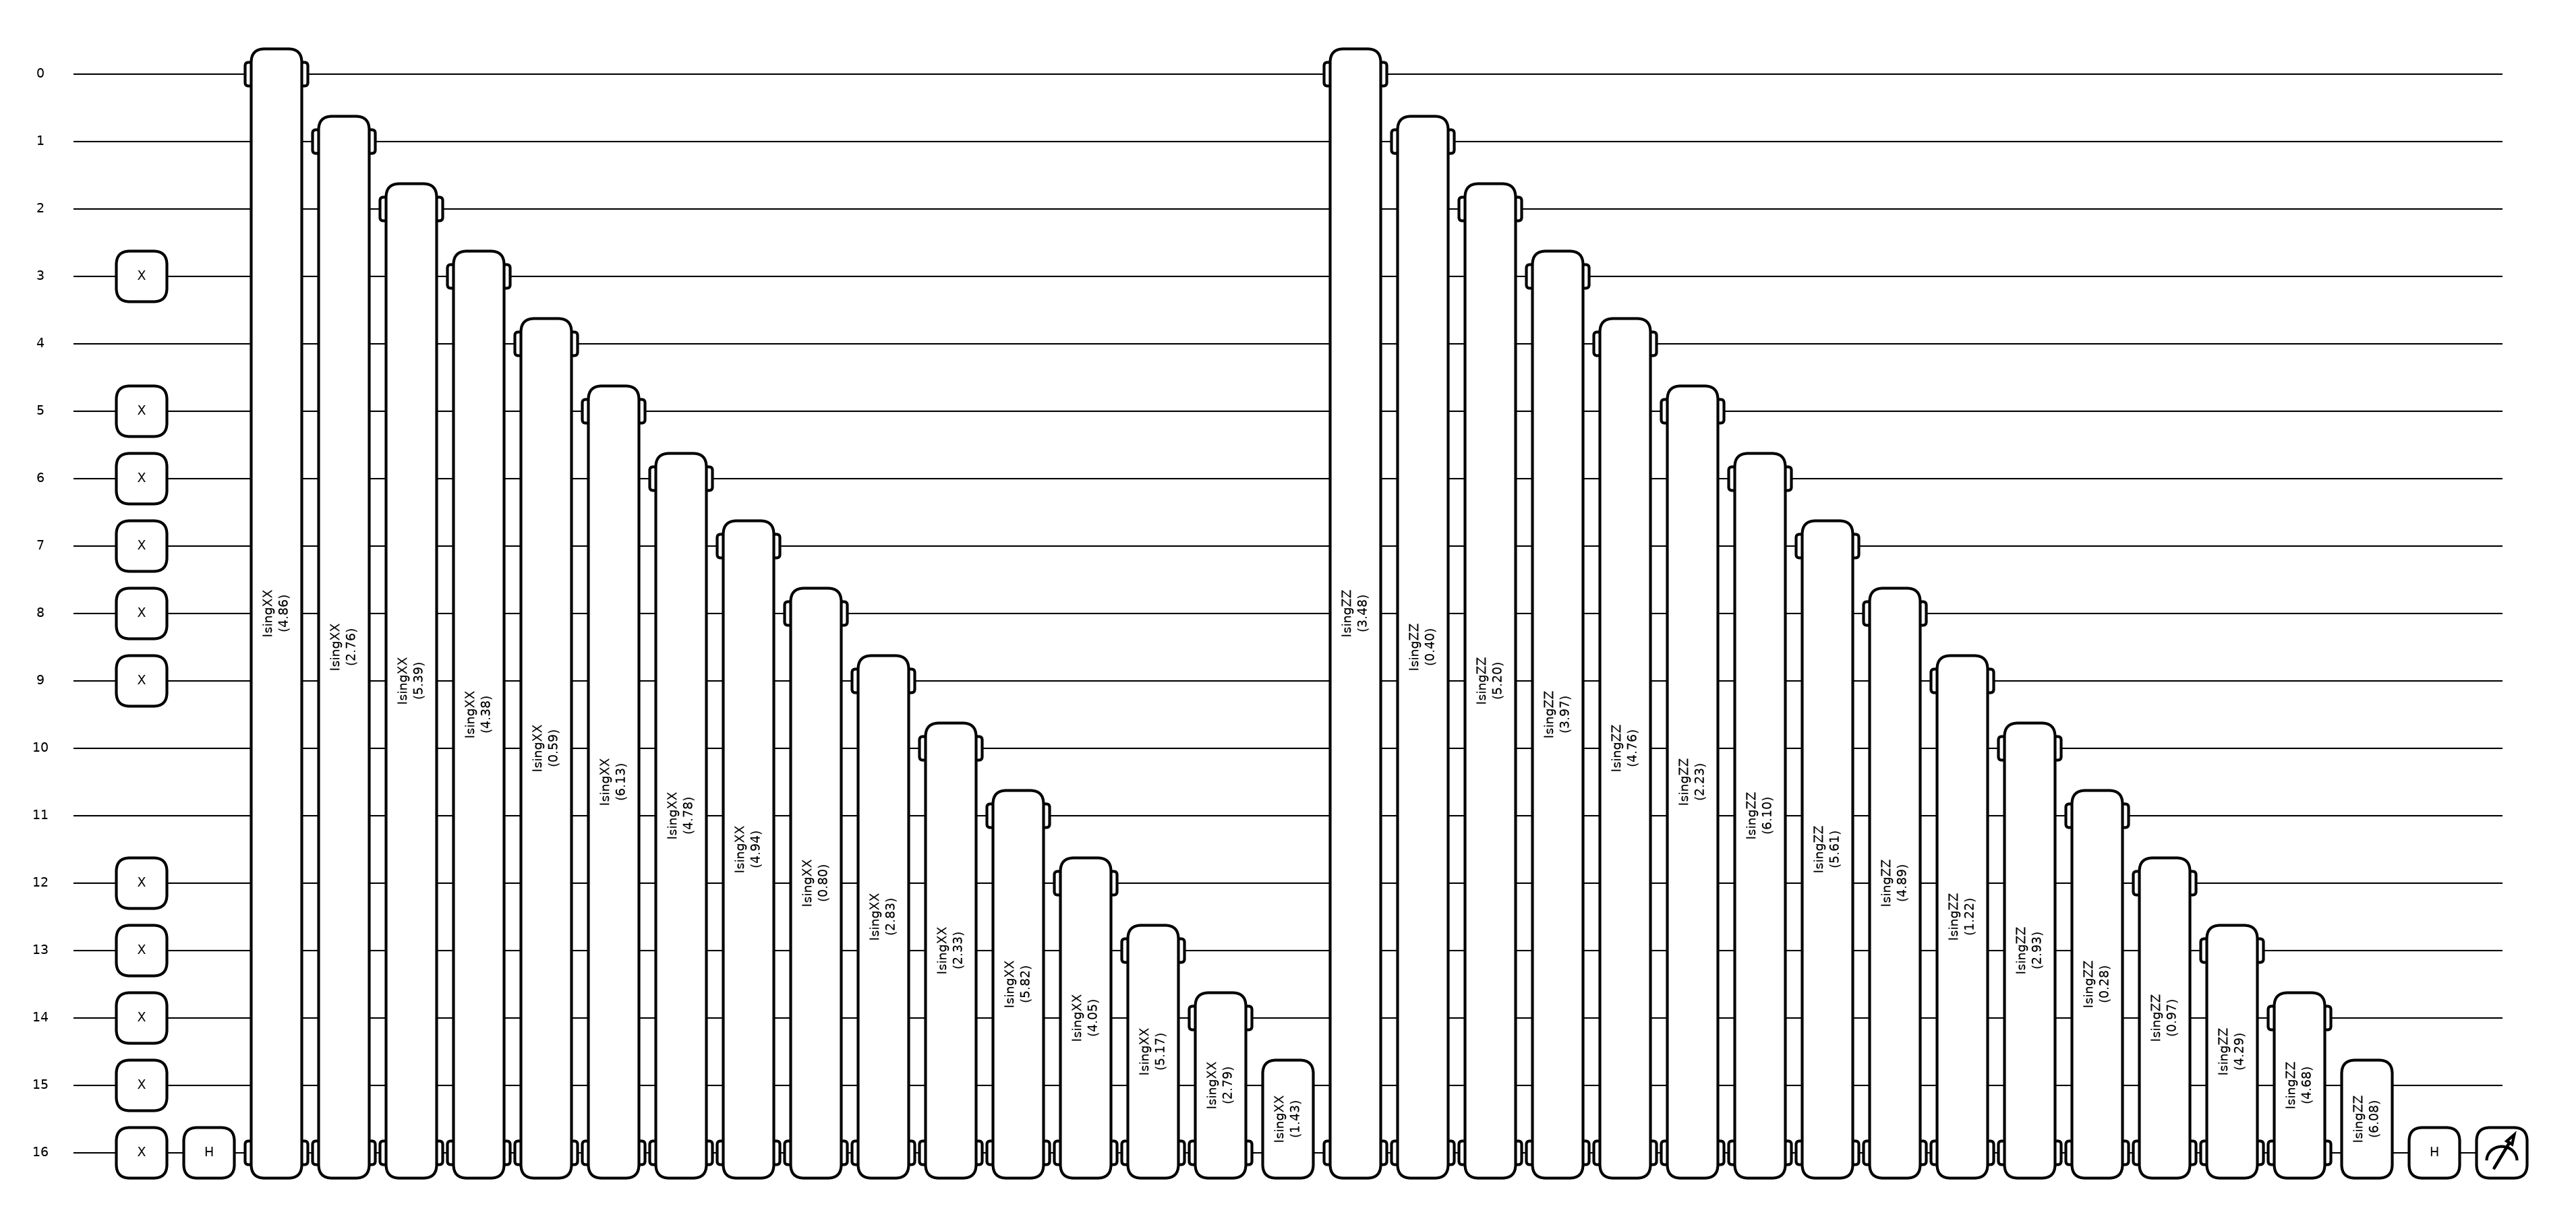

Figure-1 circuit, first training file: angles = [0.65, 1.01, 0.25, 2.94, 0.92, 1.66, 2.28, 2.41]


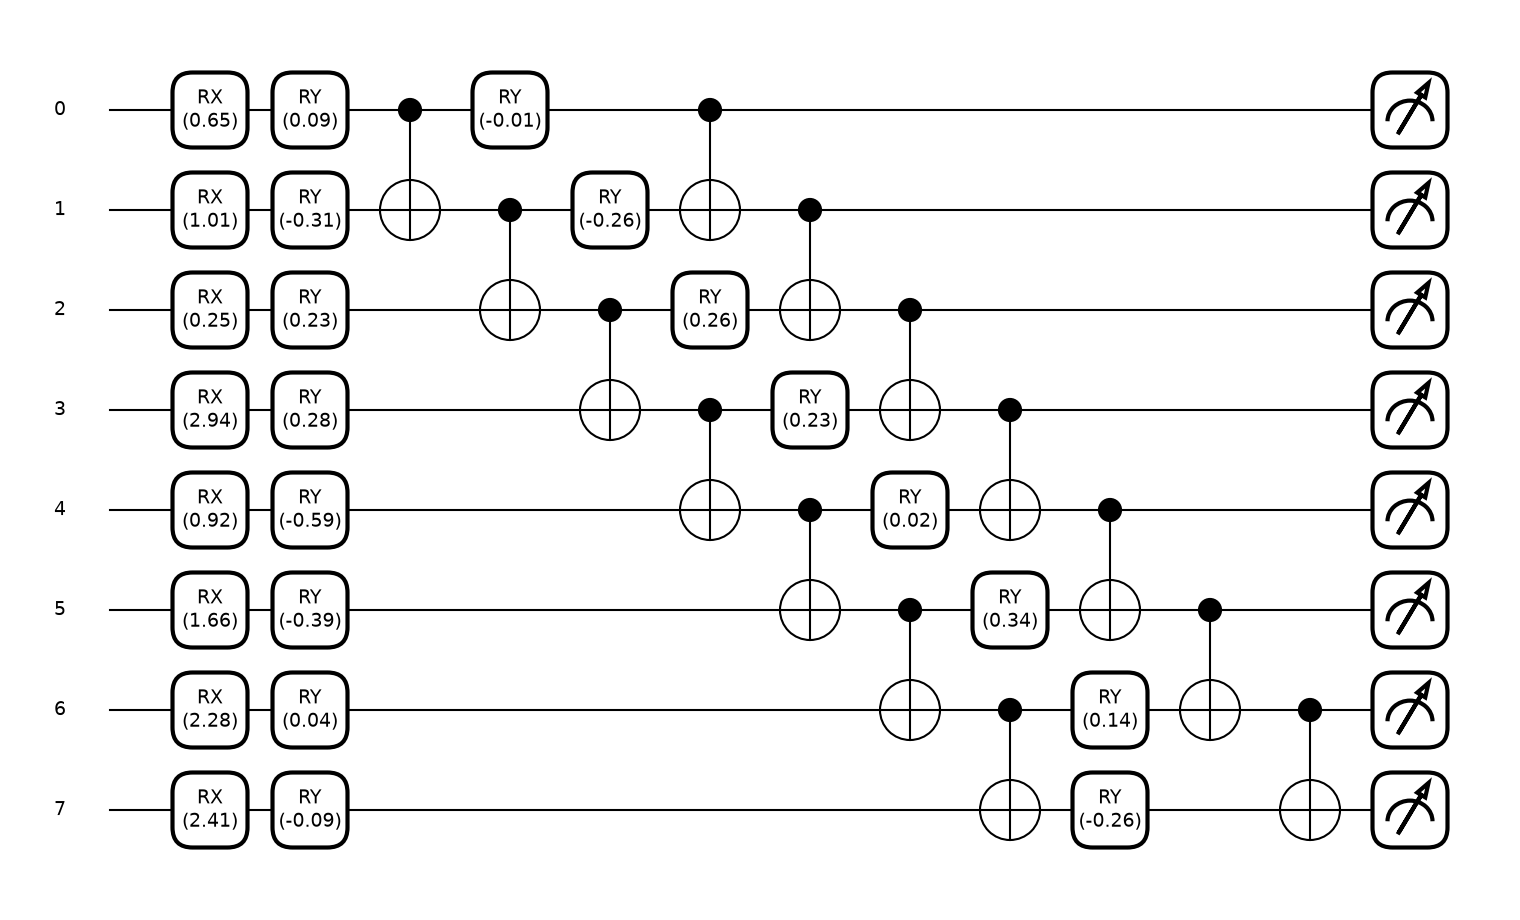

                         circuit  qubits  depth  gates   trainable_parameters                 entanglement                measurement
QNN (TFQ-tutorial model circuit)      17     35     45                     32 star (data qubit -> readout)               Z on readout
                Figure-1 circuit       8     12     38 16 (+1 classical bias)                   CNOT chain Z on every qubit, averaged


simulator outputs : [-0.058069 -0.019072 -0.039408  0.06588   0.073313 -0.032253 -0.074972
  0.082767]
closed form       : [-0.058069 -0.019072 -0.039408  0.06588   0.073313 -0.032253 -0.074972
  0.082767]
max |difference|  : outputs 1.2e-15, grad theta 2.1e-16, grad phi 7.7e-16
gradient of the hinge loss on 8 rows: simulator 1.34 s (167 ms/row) | closed form 8.9 ms
=> 100 epochs of the simulator on 2,500 rows would take about 11.6 h; the closed form takes seconds.


In [11]:
theta0, phi0 = init_params(SEED)
row0 = D["bits_train"][0]
print(f"QNN (TFQ-tutorial circuit), first training file: bits = {row0.astype(int).tolist()}")
fig, ax = qml.draw_mpl(qnn_circuit, decimals=2, level="device")(row0, theta0, phi0)
plt.show()

w_f1 = pnp.array(np.random.default_rng(SEED).normal(0, 0.3, (FIG1_LAYERS, FIG1_QUBITS)), requires_grad=True)
f1_demo = Fig1Model(D["X_train"]); a0 = f1_demo.angles(D["X_train"][:1])[0]
print(f"Figure-1 circuit, first training file: angles = {np.round(a0, 2).tolist()}")
fig, ax = qml.draw_mpl(fig1_circuit, decimals=2, level="device")(a0, w_f1)
plt.show()

def circuit_stats(qnode, *args):
    '''(qubits, depth, gates) of the circuit that the device actually runs, from PennyLane's own resource count.'''
    sp = qml.specs(qnode, level="device")(*args)
    res = sp["resources"]
    return res.num_allocs, res.depth, res.num_gates
q1, d1, g1 = circuit_stats(qnn_circuit, row0, theta0, phi0)
q2, d2, g2 = circuit_stats(fig1_circuit, a0, w_f1)
print(pd.DataFrame([dict(circuit="QNN (TFQ-tutorial model circuit)", qubits=q1, depth=d1, gates=g1, trainable_parameters=int(theta0.size + phi0.size),
                         entanglement="star (data qubit -> readout)", measurement="Z on readout"),
                    dict(circuit="Figure-1 circuit", qubits=q2, depth=d2, gates=g2, trainable_parameters=f"{int(w_f1.size)} (+1 classical bias)",
                         entanglement="CNOT chain", measurement="Z on every qubit, averaged")]).to_string(index=False))

# ---- verify the closed form against the simulator on real test rows: outputs and gradients ----
b8, y8 = D["bits_test"][:SIM_CHECK_ROWS], 2.0 * D["y_test"][:SIM_CHECK_ROWS] - 1.0
t0 = time.perf_counter(); out_sim = np.array([float(qnn_circuit(b8[i], theta0, phi0)) for i in range(len(b8))]); t_fwd = time.perf_counter() - t0
out_cf = qnn_scores(b8, theta0, phi0)
t0 = time.perf_counter(); g_sim = qml.grad(qnn_cost_sim, argnums=[0, 1])(theta0, phi0, b8, y8); t_gsim = time.perf_counter() - t0
t0 = time.perf_counter(); g_cf = qml.grad(qnn_cost_cf, argnums=[0, 1])(theta0, phi0, b8, y8); t_gcf = time.perf_counter() - t0
print("simulator outputs :", np.round(out_sim, 6))
print("closed form       :", np.round(out_cf, 6))
print("max |difference|  : outputs %.1e, grad theta %.1e, grad phi %.1e" % (
      np.abs(out_sim - out_cf).max(), np.abs(np.asarray(g_sim[0]) - np.asarray(g_cf[0])).max(), np.abs(np.asarray(g_sim[1]) - np.asarray(g_cf[1])).max()))
assert np.allclose(out_sim, out_cf, atol=1e-8) and all(np.allclose(a, b, atol=1e-8) for a, b in zip(g_sim, g_cf))
print(f"gradient of the hinge loss on {len(b8)} rows: simulator {t_gsim:.2f} s ({1000 * t_gsim / len(b8):.0f} ms/row) | closed form {t_gcf * 1000:.1f} ms")
print(f"=> 100 epochs of the simulator on 2,500 rows would take about {100 * 2500 * t_gsim / len(b8) / 3600:.1f} h; the closed form takes seconds.")

## 4. The attacks

* **Random noise (Algorithm 1 of the paper).** `perturbed = data + epsilon * randn(data.shape)`. The paper gives neither epsilon
  nor the scale of `data`; here the noise is added to the 16 principal components, each noise column scaled by that component's
  training standard deviation (`# CHOICE`), and only a `PERTURB_FRACTION` of the rows is touched. The same noise matrix is fed
  to every model, so the comparison is paired. For the bit-encoded QNN the noise matters only where it moves a component across
  zero, flipping a bit.
* **Crafted attacks (an addition: the paper claims transferability but only ever uses random noise).** All three respect the
  same budget as the noise: no component moves by more than `epsilon x std`.
  * *FGSM on the NN*: `x + eps x std x sign(grad_x loss)`, the standard white-box attack of Goodfellow et al. (the paper's
    reference [4]) with the Keras network's exact input gradient.
  * *Bit-flip attack on the QNN*: the QNN only reads `component > 0`, so its input gradient is zero almost everywhere and FGSM
    is useless. The white-box attack instead looks at the circuit's closed form and greedily flips, per file, the bit that most
    reduces the margin `y x output`, among the components that are closer to zero than the budget (so that a perturbation
    within budget can really flip them); the flipped component is moved just across zero.
  * *FGSM on the Figure-1 circuit*: the same rule with the gradient of `-y x output` through the angle encoding.
* **Victims.** QNN, NN, Figure-1 QNN, RandomForest and SVC on the components, RandomForest and SVC on the bits.

In [12]:
def add_perturbation(X, eps, r, std, fraction=1.0):
    '''Algorithm 1: data + eps * randn(data.shape), CHOICE: noise column j scaled by the training std of component j, only a
    `fraction` of the rows perturbed.'''
    noise = r.standard_normal(X.shape)                                  # np.random.randn(*data.shape)
    scaled = eps * std[None, :] * noise
    if fraction < 1.0:
        keep = np.zeros(len(X), dtype=bool); keep[r.choice(len(X), int(round(fraction * len(X))), replace=False)] = True
        scaled[~keep] = 0.0
    return X + scaled

def nn_input_grad(model, X, y):
    '''Gradient of the per-row binary cross-entropy with respect to the inputs.'''
    Xt = tf.convert_to_tensor(np.asarray(X, dtype="float32")); yt = tf.convert_to_tensor(np.asarray(y, dtype="float32"))
    with tf.GradientTape() as tape:
        tape.watch(Xt)
        p = model(Xt, training=False)[:, 0]
        loss = -(yt * tf.math.log(p + 1e-7) + (1.0 - yt) * tf.math.log(1.0 - p + 1e-7))
    return tape.gradient(loss, Xt).numpy()

def fgsm_nn(model, X, y, eps, std):
    return X + eps * std[None, :] * np.sign(nn_input_grad(model, X, y))

def fgsm_fig1(F, X, y, eps, std):
    '''FGSM through the angle encoding; only the components that the circuit reads (the first FIG1_QUBITS) are perturbed.'''
    y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
    A = pnp.array(F.angles(X), requires_grad=True)
    g = qml.grad(lambda a: pnp.sum(-y_pm * fig1_out(F.w, F.b, a)))(A)                 # per-row loss -y*output (linear margin, never saturates)
    step = np.zeros_like(X); step[:, :FIG1_QUBITS] = np.sign(np.asarray(g))      # angle = scale * PC with scale > 0, so the signs agree
    return X + eps * std[None, :] * step

def qnn_bitflip_attack(X, y, theta, phi, eps, std):
    '''White-box budgeted bit-flip attack on the TFQ-tutorial QNN (greedy, per file; see the text above).'''
    budget = eps * std[None, :]
    bits = bits_of(X)
    can_flip = np.abs(X - BIT_THRESHOLD) < budget - 1e-6
    y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0
    cur, flipped = bits.copy(), np.zeros(bits.shape, dtype=bool)
    margin = y_pm * qnn_scores(cur, theta, phi)
    for _ in range(N_QUBITS):
        best_gain, best_j = np.zeros(len(y_pm)), np.full(len(y_pm), -1)
        for j in range(N_QUBITS):
            cand = cur.copy(); cand[:, j] = 1.0 - cand[:, j]
            gain = np.where(can_flip[:, j] & ~flipped[:, j], margin - y_pm * qnn_scores(cand, theta, phi), -np.inf)
            better = gain > best_gain
            best_gain, best_j = np.where(better, gain, best_gain), np.where(better, j, best_j)
        rows = np.flatnonzero(best_j >= 0)
        if len(rows) == 0:
            break
        cur[rows, best_j[rows]] = 1.0 - cur[rows, best_j[rows]]; flipped[rows, best_j[rows]] = True
        margin = y_pm * qnn_scores(cur, theta, phi)
    X_adv = X.copy()
    X_adv[flipped] = np.where(bits[flipped] > 0.5, BIT_THRESHOLD - 1e-6, BIT_THRESHOLD + 1e-6)     # move just across the threshold
    assert np.array_equal(bits_of(X_adv), cur), "bit-flip bookkeeping error"
    return X_adv
print("attacks defined")

attacks defined


## 5. Training and attacking every model, seed by seed

For each seed the cell below builds the split of Section 2, trains the QNN (exact formula, 100 epochs), the Keras NN
(100 epochs), the Figure-1 circuit (`FIG1_EPOCHS` epochs) and the four baselines, scores everything on the **clean test split**,
and then on the attacked test split: `NOISE_DRAWS` independent Algorithm-1 noise matrices, FGSM on the NN, the bit-flip attack
on the QNN and FGSM on the Figure-1 circuit. The crafted attacks see the true labels of the test rows (white-box, labelled
evasion). Noise draws are averaged; the standard deviation over the draws of the accuracy is kept.

In [13]:
VICTIMS_ORDER = ["QNN", "NN", "QNN-Fig1", "RF", "SVC", "RF-bits", "SVC-bits"]
VICTIM_LABEL = {"QNN": "QNN (TFQ circuit, 16 bits)", "NN": "NN (Keras 16-16-1)", "QNN-Fig1": "QNN Figure-1 circuit (8 qubits)",
                "RF": "RandomForest (16 PCs)", "SVC": "SVC rbf (16 PCs)", "RF-bits": "RandomForest (16 bits)", "SVC-bits": "SVC rbf (16 bits)"}

def eval_victims(victims, X_list, y):
    '''Average the metrics of every victim over a list of perturbed copies of the test inputs.'''
    rows = []
    for name in VICTIMS_ORDER:
        ms = [evaluate(victims[name](X), y) for X in X_list]
        d = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
        d["acc_std"] = float(np.std([m["accuracy"] for m in ms])); d["victim"] = name
        rows.append(d)
    return rows

def run_seed(seed):
    t_all = time.time(); D = make_split(seed); out = dict(seed=seed, D=D, times={})
    t0 = time.perf_counter()
    theta, phi, qh = train_qnn(D["bits_train"], D["y_train"], seed, EPOCHS, val=(D["bits_val"], D["y_val"])); out["times"]["QNN"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    nn = build_nn(seed); nh = fit_nn(nn, D["X_train"], D["y_train"], EPOCHS, val=(D["X_val"], D["y_val"]), seed=seed); out["times"]["NN"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    F = Fig1Model(D["X_train"]); fh = F.fit(D["X_train"], D["y_train"], seed, FIG1_EPOCHS, val=(D["X_val"], D["y_val"])); out["times"]["QNN-Fig1"] = time.perf_counter() - t0
    rf = RandomForestClassifier(n_estimators=200, random_state=seed).fit(D["X_train"], D["y_train"])
    sv = SVC(kernel="rbf", C=1.0, random_state=seed).fit(D["X_train"], D["y_train"])
    rfb = RandomForestClassifier(n_estimators=200, random_state=seed).fit(D["bits_train"], D["y_train"])
    svb = SVC(kernel="rbf", C=1.0, random_state=seed).fit(D["bits_train"], D["y_train"])
    victims = {"QNN": lambda X: qnn_scores(bits_of(X), theta, phi), "NN": lambda X: nn_scores(nn, X), "QNN-Fig1": lambda X: F.scores(X),
               "RF": lambda X: rf.predict_proba(X)[:, 1] - 0.5, "SVC": lambda X: sv.decision_function(X),
               "RF-bits": lambda X: rfb.predict_proba(bits_of(X))[:, 1] - 0.5, "SVC-bits": lambda X: svb.decision_function(bits_of(X))}
    out.update(theta=theta, phi=phi, nn=nn, F=F, victims=victims, hist=dict(QNN=qh, NN=nh, Fig1=fh))
    Xte, yte, std = D["X_test"], D["y_test"], D["std"]
    r = np.random.default_rng(seed + 500)
    noise_list = [add_perturbation(Xte, EPS, r, std, PERTURB_FRACTION) for _ in range(NOISE_DRAWS)]
    out["noise_list"] = noise_list
    attacks = {"clean": [Xte], "random noise": noise_list, "FGSM [NN]": [fgsm_nn(nn, Xte, yte, EPS, std)],
               "bit-flip [QNN]": [qnn_bitflip_attack(Xte, yte, theta, phi, EPS, std)], "FGSM [Fig1]": [fgsm_fig1(F, Xte, yte, EPS, std)]}
    out["attacks"] = {k: v[0] for k, v in attacks.items()}
    rows = []
    for aname, Xs in attacks.items():
        for d in eval_victims(victims, Xs, yte):
            rows.append(dict(seed=seed, attack=aname, eps=0.0 if aname == "clean" else EPS, **d))
    out["rows"] = rows
    out["scores"] = {(v, a): victims[v](out["attacks"][a] if a != "random noise" else noise_list[0]) for v in ("QNN", "NN") for a in ("clean", "random noise")}
    out["times"]["total"] = time.time() - t_all
    return out

RUNS = {}
for seed in SEEDS:
    RUNS[seed] = run_seed(seed)
    R = RUNS[seed]; rr = pd.DataFrame(R["rows"])
    acc = lambda v, a: rr[(rr.victim == v) & (rr.attack == a)].accuracy.iloc[0]
    print(f"seed {seed}: {R['times']['total']:.0f} s (QNN {R['times']['QNN']:.0f} s, NN {R['times']['NN']:.0f} s, Fig1 {R['times']['QNN-Fig1']:.0f} s) | "
          f"clean acc QNN {acc('QNN', 'clean'):.3f} NN {acc('NN', 'clean'):.3f} Fig1 {acc('QNN-Fig1', 'clean'):.3f} RF {acc('RF', 'clean'):.3f} | "
          f"noise: QNN {acc('QNN', 'random noise'):.3f} NN {acc('NN', 'random noise'):.3f} Fig1 {acc('QNN-Fig1', 'random noise'):.3f}", flush=True)
results = pd.DataFrame([row for R in RUNS.values() for row in R["rows"]])
M = RUNS[SEED]                                       # the main run used for the figures and for the paper-vs-notebook table
print("results table:", results.shape)

# ---- re-check on the 17-qubit simulator: the attacked predictions of the QNN are the simulator's predictions ----
Xchk = [M["attacks"]["bit-flip [QNN]"][:SIM_CHECK_ROWS], M["noise_list"][0][:SIM_CHECK_ROWS]]
for name, Xc in zip(["bit-flip attacked", "noise perturbed"], Xchk):
    sim_pred = np.array([float(qnn_circuit(b, M["theta"], M["phi"])) for b in bits_of(Xc)]) > 0
    cf_pred = qnn_scores(bits_of(Xc), M["theta"], M["phi"]) > 0
    print(f"{name} test rows: simulator predictions == closed form predictions:", bool(np.array_equal(sim_pred, cf_pred)))
    assert np.array_equal(sim_pred, cf_pred)

seed 42: 366 s (QNN 40 s, NN 51 s, Fig1 248 s) | clean acc QNN 0.769 NN 0.966 Fig1 0.712 RF 0.971 | noise: QNN 0.597 NN 0.844 Fig1 0.711


seed 43: 345 s (QNN 39 s, NN 58 s, Fig1 226 s) | clean acc QNN 0.713 NN 0.960 Fig1 0.721 RF 0.960 | noise: QNN 0.532 NN 0.840 Fig1 0.638


seed 44: 344 s (QNN 30 s, NN 55 s, Fig1 237 s) | clean acc QNN 0.771 NN 0.972 Fig1 0.680 RF 0.974 | noise: QNN 0.566 NN 0.842 Fig1 0.567


results table: (105, 13)


bit-flip attacked test rows: simulator predictions == closed form predictions: True


noise perturbed test rows: simulator predictions == closed form predictions: True


## 6. Results: the paper's Tables 1 and 2 and Figures 2 to 7, re-drawn

The paper's Table 1 lists accuracy, precision, recall and F1 of the NN and the QNN before the attack; Table 2 after it.
The same two tables are produced below for the main seed (the "after" columns are the Algorithm-1 noise at `EPS`, averaged
over `NOISE_DRAWS` independent noise matrices), followed by the overview of every attack against every victim, the training
curves, the confusion matrices (Figures 2 and 3), the ROC curves (Figures 4 and 5) and the precision-recall curves
(Figures 6 and 7). Malware is the positive class everywhere.

In [14]:
METRICS4 = ["accuracy", "precision", "recall", "f1"]
def one(v, a, seed=SEED):
    return results[(results.seed == seed) & (results.victim == v) & (results.attack == a)].iloc[0]

def paper_style(attack):
    return pd.DataFrame([{"model": v, **{m: round(float(one(v, attack)[m]), 2) for m in METRICS4}} for v in ("NN", "QNN")]).set_index("model")

print("This notebook's Table 1: before the attack (clean test split, main seed)")
display(paper_style("clean"))
print(f"This notebook's Table 2: after the attack = Algorithm 1 noise, eps = {EPS} (mean of {NOISE_DRAWS} draws, main seed)")
display(paper_style("random noise"))

# every attack against every victim, accuracy (mean +- std over seeds; with one seed the std is over the noise draws)
def acc_cell(v, a):
    sub = results[(results.victim == v) & (results.attack == a)]
    sd = sub.accuracy.std(ddof=0) if len(sub) > 1 else float(sub.acc_std.iloc[0])
    return f"{sub.accuracy.mean():.3f} +- {sd:.3f}"
overview = pd.DataFrame({VICTIM_LABEL[v]: {a: acc_cell(v, a) for a in ["clean", "random noise", "FGSM [NN]", "bit-flip [QNN]", "FGSM [Fig1]"]} for v in VICTIMS_ORDER})
print(f"\nTest accuracy of every victim (columns) under every attack (rows), eps = {EPS}; mean +- std over {len(SEEDS)} seed(s)"
      + ("" if len(SEEDS) > 1 else " (std over noise draws; crafted attacks are deterministic)"))
display(overview)

This notebook's Table 1: before the attack (clean test split, main seed)


,accuracy,precision,recall,f1
model,,,,
NN,0.97,0.96,0.97,0.97
QNN,0.77,0.77,0.80,0.78


This notebook's Table 2: after the attack = Algorithm 1 noise, eps = 0.5 (mean of 10 draws, main seed)


,accuracy,precision,recall,f1
model,,,,
NN,0.84,0.85,0.85,0.85
QNN,0.60,0.61,0.66,0.63



Test accuracy of every victim (columns) under every attack (rows), eps = 0.5; mean +- std over 3 seed(s)


,"QNN (TFQ circuit, 16 bits)",NN (Keras 16-16-1),QNN Figure-1 circuit (8 qubits),RandomForest (16 PCs),SVC rbf (16 PCs),RandomForest (16 bits),SVC rbf (16 bits)
clean,0.751 +- 0.027,0.966 +- 0.005,0.704 +- 0.018,0.968 +- 0.006,0.951 +- 0.003,0.953 +- 0.003,0.947 +- 0.006
random noise,0.565 +- 0.026,0.842 +- 0.001,0.639 +- 0.059,0.871 +- 0.009,0.888 +- 0.004,0.814 +- 0.007,0.818 +- 0.011
FGSM [NN],0.517 +- 0.035,0.114 +- 0.011,0.511 +- 0.281,0.425 +- 0.024,0.293 +- 0.020,0.431 +- 0.051,0.372 +- 0.048
bit-flip [QNN],0.032 +- 0.016,0.954 +- 0.006,0.698 +- 0.037,0.966 +- 0.004,0.948 +- 0.001,0.819 +- 0.042,0.831 +- 0.033
FGSM [Fig1],0.600 +- 0.076,0.775 +- 0.089,0.207 +- 0.188,0.825 +- 0.091,0.851 +- 0.020,0.849 +- 0.084,0.842 +- 0.081


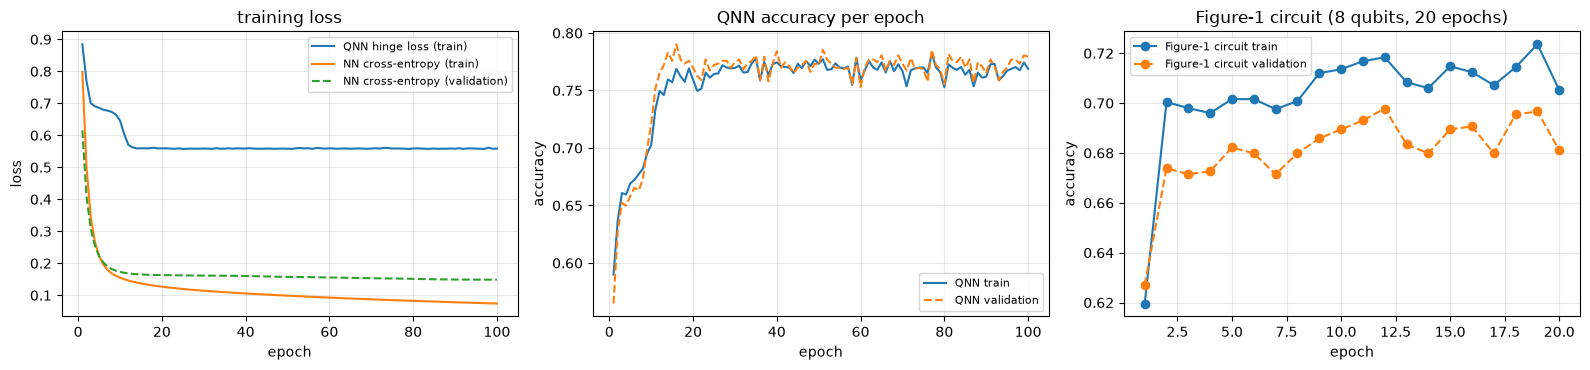

final validation accuracy: QNN 0.779 | Figure-1 circuit 0.681 | NN (clean test) 0.966


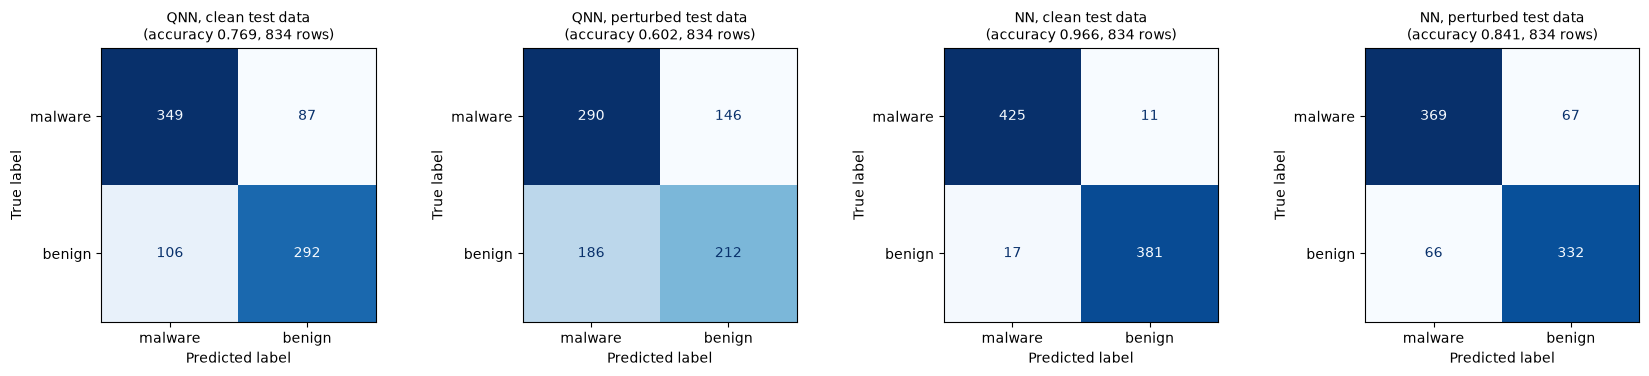

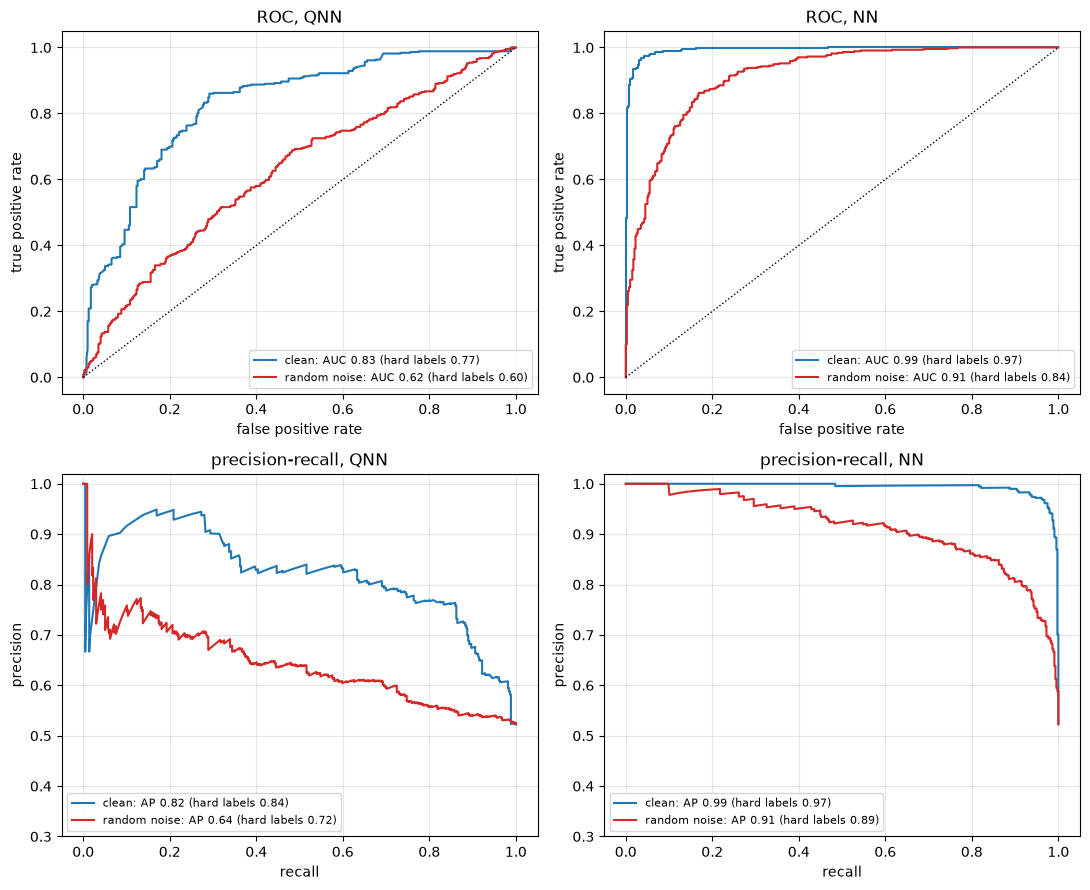

In [15]:
# ---- training curves ----
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
h = M["hist"]
axes[0].plot(h["QNN"].epoch, h["QNN"].loss, label="QNN hinge loss (train)"); axes[0].plot(h["NN"].epoch, h["NN"].loss, label="NN cross-entropy (train)")
axes[0].plot(h["NN"].epoch, h["NN"].val_loss, "--", label="NN cross-entropy (validation)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("training loss"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(h["QNN"].epoch, h["QNN"].train_acc, label="QNN train"); axes[1].plot(h["QNN"].epoch, h["QNN"].val_acc, "--", label="QNN validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("QNN accuracy per epoch"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
axes[2].plot(h["Fig1"].epoch, h["Fig1"].train_acc, "o-", label="Figure-1 circuit train"); axes[2].plot(h["Fig1"].epoch, h["Fig1"].val_acc, "o--", label="Figure-1 circuit validation")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("accuracy"); axes[2].set_title(f"Figure-1 circuit ({FIG1_QUBITS} qubits, {FIG1_EPOCHS} epochs)"); axes[2].legend(fontsize=8); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"final validation accuracy: QNN {h['QNN'].val_acc.iloc[-1]:.3f} | Figure-1 circuit {h['Fig1'].val_acc.iloc[-1]:.3f} | "
      f"NN (clean test) {one('NN', 'clean').accuracy:.3f}")

# ---- confusion matrices, Figures 2 and 3 ----
yte = M["D"]["y_test"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (v, a, ttl) in zip(axes, [("QNN", "clean", "QNN, clean test data"), ("QNN", "random noise", "QNN, perturbed test data"),
                                  ("NN", "clean", "NN, clean test data"), ("NN", "random noise", "NN, perturbed test data")]):
    pred = (M["scores"][(v, a)] > 0).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(yte, pred, labels=[1, 0]), display_labels=["malware", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{ttl}\n(accuracy {accuracy_score(yte, pred):.3f}, {len(yte)} rows)", fontsize=10)
plt.tight_layout(); plt.show()

# ---- ROC (Figures 4, 5) and precision-recall (Figures 6, 7) curves from the real-valued scores ----
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, v in enumerate(["QNN", "NN"]):
    for a, col in [("clean", "tab:blue"), ("random noise", "tab:red")]:
        sc = M["scores"][(v, a)]; ev = evaluate(sc, yte)
        fpr, tpr, _ = roc_curve(yte, sc); axes[0, j].plot(fpr, tpr, color=col, label=f"{a}: AUC {ev['roc_auc']:.2f} (hard labels {ev['roc_auc_hard']:.2f})")
        p_, r_, _ = precision_recall_curve(yte, sc); axes[1, j].plot(r_, p_, color=col, label=f"{a}: AP {ev['pr_auc']:.2f} (hard labels {ev['pr_auc_hard']:.2f})")
    axes[0, j].plot([0, 1], [0, 1], "k:", lw=1); axes[0, j].set_xlabel("false positive rate"); axes[0, j].set_ylabel("true positive rate")
    axes[0, j].set_title(f"ROC, {v}"); axes[0, j].legend(fontsize=8, loc="lower right"); axes[0, j].grid(alpha=0.3)
    axes[1, j].set_xlabel("recall"); axes[1, j].set_ylabel("precision"); axes[1, j].set_ylim(0.3, 1.02)
    axes[1, j].set_title(f"precision-recall, {v}"); axes[1, j].legend(fontsize=8, loc="lower left"); axes[1, j].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Who breaks whom: noise, FGSM and the bit-flip attack against every victim

The paper claims that "adversarial samples crafted for one model type can impair the performance of the other" but only ever
uses random noise, which is model-agnostic. The matrix below uses the main seed and the same budget (`EPS` x component std per
component) for every attack: rows are the attack and *the model it was crafted against*, columns are the victims. A drop in a
column other than the row's own model is a successful transfer. The bar chart shows accuracy and the F1 of the malware class.

Accuracy, main seed, eps = 0.5 (rows: attack and the model it was crafted against; columns: victim)


,"QNN (TFQ circuit, 16 bits)",NN (Keras 16-16-1),QNN Figure-1 circuit (8 qubits),RandomForest (16 PCs),SVC rbf (16 PCs),RandomForest (16 bits),SVC rbf (16 bits)
clean,0.769,0.966,0.712,0.971,0.947,0.956,0.947
random noise,0.597,0.844,0.711,0.881,0.892,0.821,0.833
FGSM [NN],0.566,0.100,0.676,0.430,0.320,0.428,0.348
bit-flip [QNN],0.055,0.960,0.709,0.969,0.948,0.833,0.862
FGSM [Fig1],0.520,0.689,0.468,0.904,0.855,0.930,0.909


Accuracy drop = clean accuracy minus attacked accuracy (positive = the attack hurts):


,"QNN (TFQ circuit, 16 bits)",NN (Keras 16-16-1),QNN Figure-1 circuit (8 qubits),RandomForest (16 PCs),SVC rbf (16 PCs),RandomForest (16 bits),SVC rbf (16 bits)
random noise,0.172,0.123,0.001,0.090,0.055,0.134,0.115
FGSM [NN],0.203,0.867,0.036,0.541,0.627,0.528,0.600
bit-flip [QNN],0.713,0.006,0.004,0.002,-0.001,0.122,0.085
FGSM [Fig1],0.248,0.277,0.245,0.067,0.092,0.025,0.038


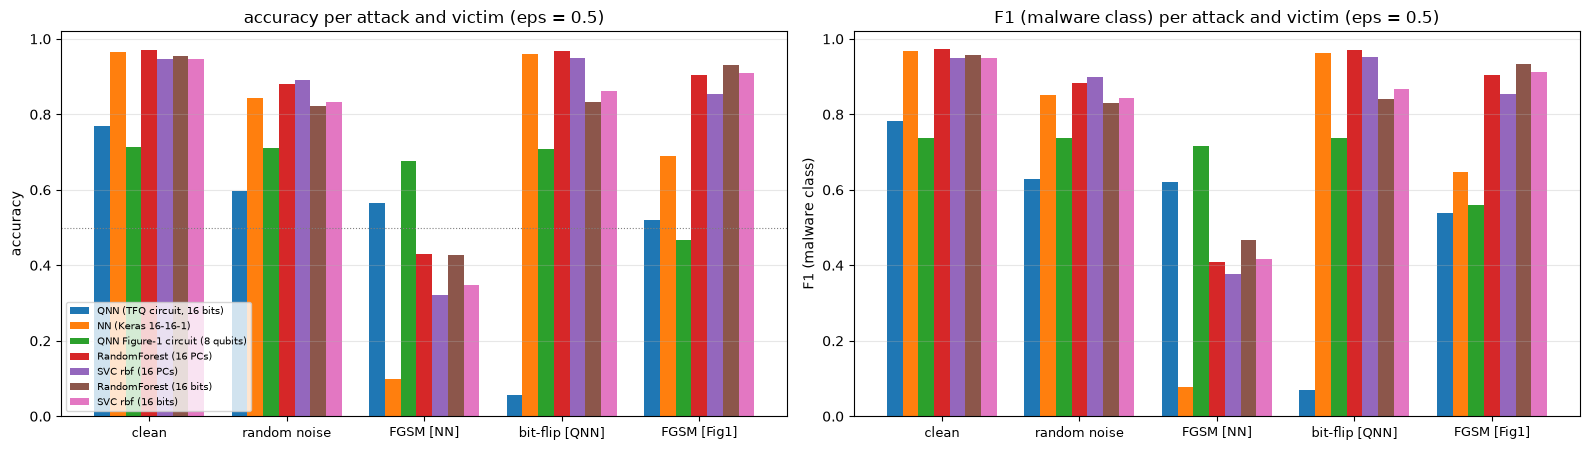

In [16]:
atk_order = ["clean", "random noise", "FGSM [NN]", "bit-flip [QNN]", "FGSM [Fig1]"]
acc_mat = pd.DataFrame({VICTIM_LABEL[v]: [one(v, a).accuracy for a in atk_order] for v in VICTIMS_ORDER}, index=atk_order)
f1_mat = pd.DataFrame({VICTIM_LABEL[v]: [one(v, a).f1 for a in atk_order] for v in VICTIMS_ORDER}, index=atk_order)
print(f"Accuracy, main seed, eps = {EPS} (rows: attack and the model it was crafted against; columns: victim)")
display(acc_mat.round(3))
drop = (acc_mat.loc["clean"] - acc_mat).drop(index="clean")
print("Accuracy drop = clean accuracy minus attacked accuracy (positive = the attack hurts):")
display(drop.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
w = 0.8 / len(VICTIMS_ORDER)
for k, v in enumerate(VICTIMS_ORDER):
    axes[0].bar(np.arange(len(atk_order)) + k * w, [one(v, a).accuracy for a in atk_order], w, label=VICTIM_LABEL[v])
    axes[1].bar(np.arange(len(atk_order)) + k * w, [one(v, a).f1 for a in atk_order], w, label=VICTIM_LABEL[v])
for ax, ttl in zip(axes, ["accuracy", "F1 (malware class)"]):
    ax.set_xticks(np.arange(len(atk_order)) + 0.4 - w / 2); ax.set_xticklabels(atk_order, fontsize=9); ax.set_ylabel(ttl); ax.set_ylim(0, 1.02)
    ax.set_title(f"{ttl} per attack and victim (eps = {EPS})"); ax.grid(alpha=0.3, axis="y")
axes[0].axhline(0.5, color="gray", lw=0.8, ls=":"); axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

## 8. How much does epsilon matter, and how much of the data is perturbed?

The paper never states epsilon, although every "after" number depends on it, and says only that noise is added to "a small
portion of the dataset". The sweep below repeats the attacks of Section 7 on the main seed's trained models for several
values of epsilon (crafted attacks are recomputed for every epsilon), and a second sweep perturbs only a fraction of the
test rows by Algorithm 1 at `EPS`.

epsilon sweep: 135 s


victim                 QNN     NN  QNN-Fig1
attack         eps                         
FGSM [Fig1]    0.00  0.769  0.966     0.712
               0.10  0.740  0.940     0.664
               0.25  0.624  0.845     0.601
               0.50  0.520  0.689     0.468
               0.75  0.470  0.586     0.309
               1.00  0.447  0.538     0.325
               1.50  0.363  0.525     0.484
               2.00  0.355  0.517     0.649
FGSM [NN]      0.00  0.769  0.966     0.712
               0.10  0.766  0.805     0.703
               0.25  0.668  0.378     0.681
               0.50  0.566  0.100     0.676
               0.75  0.592  0.056     0.637
               1.00  0.668  0.032     0.582
               1.50  0.651  0.018     0.468
               2.00  0.677  0.016     0.375
bit-flip [QNN] 0.00  0.769  0.966     0.712
               0.10  0.543  0.965     0.712
               0.25  0.199  0.960     0.713
               0.50  0.055  0.960     0.709
               0.75  0.024  0.948     0.707
               1.00  0.008  0.923     0.707
               1.50  0.004  0.928     0.701
               2.00  0.002  0.930     0.698
random noise   0.00  0.769  0.966     0.712
               0.10  0.745  0.956     0.719
               0.25  0.660  0.920     0.716
               0.50  0.593  0.840     0.706
               0.75  0.564  0.777     0.683
               1.00  0.536  0.727     0.652
               1.50  0.522  0.668     0.604
               2.00  0.517  0.628     0.575

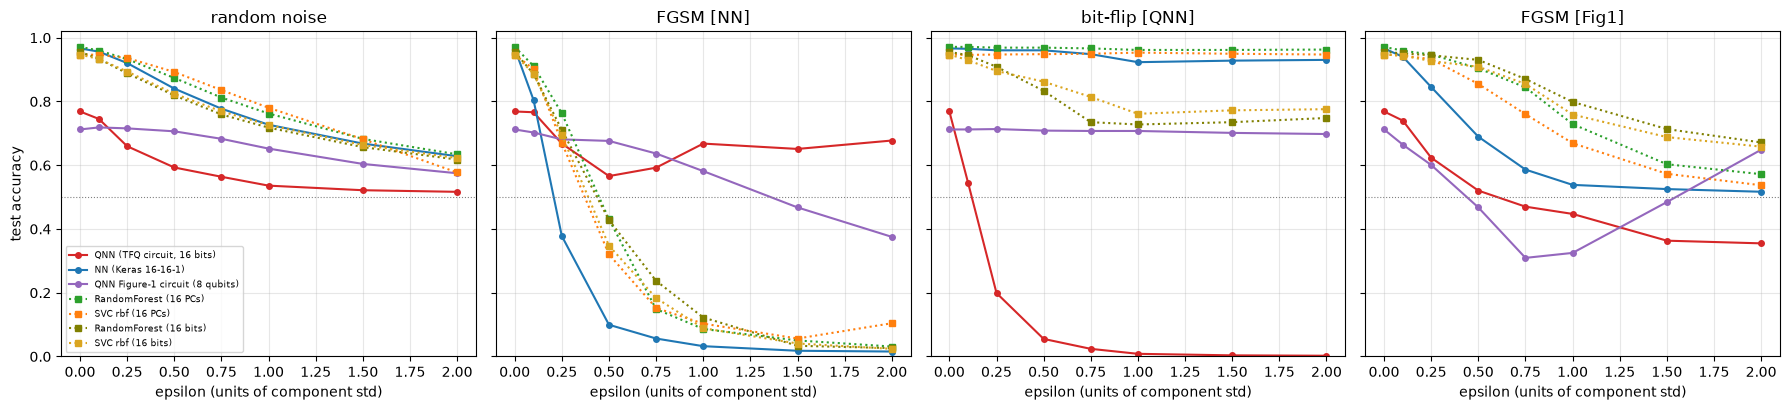

Accuracy when only a fraction of the test rows receives Algorithm-1 noise (eps = 0.5):


victim,QNN,NN,QNN-Fig1,RF,SVC
fraction,,,,,
0.10,0.748,0.953,0.711,0.961,0.941
0.25,0.730,0.936,0.711,0.945,0.933
0.50,0.684,0.908,0.705,0.927,0.918
1.00,0.604,0.844,0.706,0.875,0.889


In [17]:
D0, yte, Xte, std = M["D"], M["D"]["y_test"], M["D"]["X_test"], M["D"]["std"]
sweep_rows = []
t0 = time.time()
for eps in EPS_SWEEP:
    r = np.random.default_rng(SEED + 700)
    sets = {"random noise": [add_perturbation(Xte, eps, r, std, PERTURB_FRACTION) for _ in range(NOISE_DRAWS)],
            "FGSM [NN]": [fgsm_nn(M["nn"], Xte, yte, eps, std)], "bit-flip [QNN]": [qnn_bitflip_attack(Xte, yte, M["theta"], M["phi"], eps, std)],
            "FGSM [Fig1]": [fgsm_fig1(M["F"], Xte, yte, eps, std)]}
    for a, Xs in sets.items():
        for d in eval_victims(M["victims"], Xs, yte):
            sweep_rows.append(dict(eps=eps, attack=a, **d))
sweep = pd.DataFrame(sweep_rows)
print(f"epsilon sweep: {time.time() - t0:.0f} s")
display(sweep[sweep.victim.isin(["QNN", "NN", "QNN-Fig1"])].pivot_table(index=["attack", "eps"], columns="victim", values="accuracy").round(3)[["QNN", "NN", "QNN-Fig1"]])

VCOL = {"QNN": "tab:red", "NN": "tab:blue", "QNN-Fig1": "tab:purple", "RF": "tab:green", "SVC": "tab:orange", "RF-bits": "olive", "SVC-bits": "goldenrod"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, a in zip(axes, ["random noise", "FGSM [NN]", "bit-flip [QNN]", "FGSM [Fig1]"]):
    for v in VICTIMS_ORDER:
        s_ = sweep[(sweep.attack == a) & (sweep.victim == v)]
        ax.plot(s_.eps, s_.accuracy, "o-" if v in ("QNN", "NN", "QNN-Fig1") else "s:", color=VCOL[v], label=VICTIM_LABEL[v], ms=4)
    ax.axhline(0.5, color="gray", lw=0.8, ls=":"); ax.set_title(a); ax.set_xlabel("epsilon (units of component std)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=6.5, loc="lower left"); axes[0].set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

# ---- how much of the data is perturbed ----
frac_rows = []
for fr in FRACTION_SWEEP:
    r = np.random.default_rng(SEED + 800)
    for d in eval_victims(M["victims"], [add_perturbation(Xte, EPS, r, std, fr) for _ in range(NOISE_DRAWS)], yte):
        frac_rows.append(dict(fraction=fr, **d))
frac = pd.DataFrame(frac_rows)
print(f"Accuracy when only a fraction of the test rows receives Algorithm-1 noise (eps = {EPS}):")
display(frac[frac.victim.isin(["QNN", "NN", "QNN-Fig1", "RF", "SVC"])].pivot_table(index="fraction", columns="victim", values="accuracy").round(3)[["QNN", "NN", "QNN-Fig1", "RF", "SVC"]])

## 9. The paper's own reading: perturbed data in the fine-tuning set

Section III says the 20 % of the data that is not used for training / validation / testing is the one that is "fine-tuned"
with perturbed data added. The paper never says how. The reading used here: starting from the trained model, continue
training for `FT_EPOCHS` epochs on the 1,042 fine-tuning rows with the same optimiser (a fresh Adam state), once on the clean
rows and once with `FT_PERTURBED_SHARE` of them replaced by their Algorithm-1 noisy copy (labels unchanged), and evaluate the
fine-tuned model on the clean and on the noise-perturbed test split. Comparing the two fine-tuned models separates the effect
of fine-tuning itself from the effect of the noise.

In [18]:
ft_rows = []
t0 = time.time()
for seed in SEEDS:
    R = RUNS[seed]; Dk = R["D"]; r = np.random.default_rng(seed + 900)
    Xft_mixed = Dk["X_ft"].copy()
    pick = r.choice(len(Xft_mixed), int(round(FT_PERTURBED_SHARE * len(Xft_mixed))), replace=False)
    Xft_mixed[pick] = add_perturbation(Xft_mixed[pick], EPS, r, Dk["std"])
    Xnoisy = R["noise_list"][0]
    def record(stage, model, qnn_params=None, nn_model=None):
        for eval_name, Xe in [("clean test", Dk["X_test"]), ("noisy test", Xnoisy)]:
            sc = qnn_scores(bits_of(Xe), *qnn_params) if model == "QNN" else nn_scores(nn_model, Xe)
            ft_rows.append(dict(seed=seed, stage=stage, model=model, eval=eval_name, **evaluate(sc, Dk["y_test"])))
    record("before fine-tuning", "QNN", qnn_params=(R["theta"], R["phi"])); record("before fine-tuning", "NN", nn_model=R["nn"])
    for stage, Xf in [("fine-tuned on clean rows", Dk["X_ft"]), (f"fine-tuned, {int(FT_PERTURBED_SHARE * 100)} % rows perturbed", Xft_mixed)]:
        th, ph, _ = train_qnn(bits_of(Xf), Dk["y_ft"], seed, FT_EPOCHS, init=(R["theta"], R["phi"]))
        record(stage, "QNN", qnn_params=(th, ph))
        nn2 = keras.models.clone_model(R["nn"]); nn2.set_weights(R["nn"].get_weights()); nn2.compile(optimizer=keras.optimizers.Adam(LR_NN), loss="binary_crossentropy")
        fit_nn(nn2, Xf, Dk["y_ft"], FT_EPOCHS, seed=seed)
        record(stage, "NN", nn_model=nn2)
ft = pd.DataFrame(ft_rows)
print(f"fine-tuning study: {time.time() - t0:.0f} s")
display(ft.groupby(["model", "stage", "eval"])[["accuracy", "precision", "recall", "f1"]].mean().round(3).unstack("eval"))

fine-tuning study: 47 s


accuracy             precision                recall                    f1           
eval                                  clean test noisy test clean test noisy test clean test noisy test clean test noisy test
model stage                                                                                                                  
NN    before fine-tuning                   0.966      0.843      0.964      0.848      0.972      0.852      0.968      0.850
      fine-tuned on clean rows             0.966      0.833      0.960      0.835      0.975      0.848      0.967      0.841
      fine-tuned, 50 % rows perturbed      0.956      0.867      0.952      0.872      0.965      0.875      0.958      0.874
QNN   before fine-tuning                   0.751      0.572      0.763      0.590      0.761      0.589      0.762      0.588
      fine-tuned on clean rows             0.749      0.560      0.771      0.585      0.742      0.554      0.756      0.569
      fine-tuned, 50 % rows perturbed      0.764      0.590      0.780      0.620      0.765      0.567      0.772      0.591

## 10. What the paper's confusion matrices, ROC and PR curves actually show

The four confusion matrices printed in the paper (Figures 2 and 3) are small and mutually inconsistent in size (40, 40, 370 and
94 rows), but they allow every other number of the paper's evaluation to be recomputed, and the result is informative. Below the
counts are read off the figures (rows = true class 0 / 1, columns = predicted class 0 / 1; the text of Section IV-D mislabels
them), and accuracy, precision, recall, F1 and the ROC and precision-recall AUC are computed from them, both honestly and the
way the paper's figures seem to do it (the curve of the *hard* 0 / 1 predictions, which has just one interior point).

In [19]:
PAPER_CM = {("QNN", "clean"): [[21, 0], [15, 4]], ("QNN", "perturbed"): [[1, 16], [3, 20]],
            ("NN", "clean"): [[0, 160], [0, 210]], ("NN", "perturbed"): [[0, 55], [0, 39]]}      # read off Figures 2 and 3 (true x predicted)
PAPER_AUC = {("QNN", "clean"): (0.61, 0.79), ("QNN", "perturbed"): (0.46, 0.75), ("NN", "clean"): (0.50, 0.78), ("NN", "perturbed"): (0.50, 0.71)}   # ROC AUC, PR AUC
rows = []
for (v, a), cm in PAPER_CM.items():
    (tn, fp), (fn, tp) = cm
    y_true = np.r_[np.zeros(tn + fp), np.ones(fn + tp)].astype(int); y_pred = np.r_[np.zeros(tn), np.ones(fp), np.zeros(fn), np.ones(tp)].astype(int)
    ev = evaluate(y_pred - 0.5, y_true)                                                      # hard predictions as the "score"
    swapped = dict(precision=precision_score(y_pred, y_true, zero_division=0), recall=recall_score(y_pred, y_true, zero_division=0))    # arguments swapped
    rows.append(dict(model=v, data=a, rows=len(y_true), accuracy=ev["accuracy"], precision=ev["precision"], recall=ev["recall"], f1=ev["f1"],
                     precision_args_swapped=swapped["precision"], recall_args_swapped=swapped["recall"],
                     roc_auc_from_hard_labels=ev["roc_auc"], paper_roc_auc=PAPER_AUC[(v, a)][0], pr_auc_from_hard_labels=ev["pr_auc_hard"], paper_pr_auc=PAPER_AUC[(v, a)][1]))
paper_cm_df = pd.DataFrame(rows).round(3)
display(paper_cm_df.set_index(["model", "data"]))
bal = [(tp / (tp + fn) + tn / (tn + fp)) / 2 for (tn, fp), (fn, tp) in PAPER_CM.values()]
print("ROC AUC of hard labels = balanced accuracy:", np.round(bal, 3), "-> paper's ROC AUCs 0.61, 0.46, 0.50, 0.50")
print("The NN rows of the paper's confusion matrices have an empty first column: the paper's NN predicts 'malware' for every file.")

# the same two definitions for this notebook's QNN and NN
ours_auc = pd.DataFrame([{"model": v, "data": a, "ROC AUC (scores)": one(v, at).roc_auc, "ROC AUC (hard labels)": one(v, at).roc_auc_hard,
                          "PR AUC (scores, AP)": one(v, at).pr_auc, "PR AUC (hard labels)": one(v, at).pr_auc_hard}
                         for v in ("QNN", "NN") for a, at in [("clean", "clean"), ("perturbed", "random noise")]]).round(3)
display(ours_auc.set_index(["model", "data"]))

rows  accuracy  precision  recall     f1  precision_args_swapped  recall_args_swapped  roc_auc_from_hard_labels  paper_roc_auc  pr_auc_from_hard_labels  paper_pr_auc
model data                                                                                                                                                                            
QNN   clean        40     0.625      1.000   0.211  0.348                   0.211                1.000                     0.605           0.61                    0.793          0.79
      perturbed    40     0.525      0.556   0.870  0.678                   0.870                0.556                     0.464           0.46                    0.750          0.75
NN    clean       370     0.568      0.568   1.000  0.724                   1.000                0.568                     0.500           0.50                    0.784          0.78
      perturbed    94     0.415      0.415   1.000  0.586                   1.000                0.415                     0.500           0.50                    0.707          0.71

ROC AUC of hard labels = balanced accuracy: [0.605 0.464 0.5   0.5  ] -> paper's ROC AUCs 0.61, 0.46, 0.50, 0.50
The NN rows of the paper's confusion matrices have an empty first column: the paper's NN predicts 'malware' for every file.


ROC AUC (scores)  ROC AUC (hard labels)  PR AUC (scores, AP)  PR AUC (hard labels)
model data                                                                                         
QNN   clean                 0.828                  0.767                0.823                 0.836
      perturbed             0.621                  0.594                0.626                 0.721
NN    clean                 0.993                  0.966                0.994                 0.975
      perturbed             0.923                  0.843                0.924                 0.890

## 11. Paper versus this notebook

Each row of the first table is one number from the paper's Table 1, Table 2 or Figures 4 to 7. The verdict is **reproduced**
when our value (main seed) lies within 0.02 of the paper's (the brief's tolerance: 2 accuracy points / 0.02 F1), **exceeded**
when it is more than 0.02 above, **not reached** when more than 0.02 below. AUC values are compared with the hard-label AUC,
the definition the paper's figures use (Section 10). The confusion-matrix counts of the paper belong to test sets of 40, 370
and 94 rows that cannot be reconstructed, so they cannot be checked. The second table tests the paper's qualitative claims
on the mean over seeds.

In [20]:
TOL = 0.02
def verdict(paper, ours_, tol=TOL):
    if abs(ours_ - paper) <= tol: return "reproduced"
    return f"exceeded (+{ours_ - paper:.2f})" if ours_ > paper else f"not reached ({ours_ - paper:.2f})"

PAPER_T = {("NN", "clean"):  dict(accuracy=0.54, precision=1.00, recall=0.57, f1=0.65), ("QNN", "clean"):  dict(accuracy=0.57, precision=0.92, recall=0.57, f1=0.65),
           ("NN", "random noise"): dict(accuracy=0.52, precision=0.27, recall=0.52, f1=0.36), ("QNN", "random noise"): dict(accuracy=0.45, precision=0.47, recall=0.90, f1=0.62)}
comp = []
for (v, a), vals in PAPER_T.items():
    sub = results[(results.victim == v) & (results.attack == a)]
    for m, pv in vals.items():
        o = float(one(v, a)[m])
        comp.append(dict(item=f"Table {'1' if a == 'clean' else '2'}: {v} {m} ({'before' if a == 'clean' else 'after'} attack)", paper=pv, notebook=round(o, 3),
                         mean_over_seeds=f"{sub[m].mean():.3f}", verdict=verdict(pv, o)))
for (v, a), (roc_p, pr_p) in PAPER_AUC.items():
    at = "clean" if a == "clean" else "random noise"; o_roc, o_pr = float(one(v, at).roc_auc_hard), float(one(v, at).pr_auc_hard)
    comp.append(dict(item=f"Fig. {4 if v == 'QNN' else 5}: {v} ROC AUC ({a}), hard-label definition", paper=roc_p, notebook=round(o_roc, 3), mean_over_seeds=f"{results[(results.victim == v) & (results.attack == at)].roc_auc_hard.mean():.3f}", verdict=verdict(roc_p, o_roc)))
    comp.append(dict(item=f"Fig. {6 if v == 'QNN' else 7}: {v} PR AUC ({a}), hard-label definition", paper=pr_p, notebook=round(o_pr, 3), mean_over_seeds=f"{results[(results.victim == v) & (results.attack == at)].pr_auc_hard.mean():.3f}", verdict=verdict(pr_p, o_pr)))
comp.append(dict(item="Figs. 2, 3: confusion-matrix counts (40, 40, 370 and 94 test rows)", paper="see Section 10", notebook=f"{len(M['D']['y_test'])} test rows", mean_over_seeds="", verdict="cannot be checked (test-set sizes of the paper unknown and inconsistent)"))
comparison = pd.DataFrame(comp)
pd.set_option("display.max_colwidth", 120)
display(comparison.set_index("item"))
cnt = comparison[comparison.verdict.str.startswith(("reproduced", "exceeded", "not reached"))].verdict.str.split(" (", regex=False).str[0].value_counts()
print("verdict counts over the numeric rows:", cnt.to_dict())

,paper,notebook,mean_over_seeds,verdict
item,,,,
Table 1: NN accuracy (before attack),0.54,0.966,0.966,exceeded (+0.43)
Table 1: NN precision (before attack),1.0,0.962,0.964,not reached (-0.04)
Table 1: NN recall (before attack),0.57,0.975,0.972,exceeded (+0.40)
Table 1: NN f1 (before attack),0.65,0.968,0.968,exceeded (+0.32)
Table 1: QNN accuracy (before attack),0.57,0.769,0.751,exceeded (+0.20)
Table 1: QNN precision (before attack),0.92,0.767,0.763,not reached (-0.15)
Table 1: QNN recall (before attack),0.57,0.8,0.761,exceeded (+0.23)
Table 1: QNN f1 (before attack),0.65,0.783,0.762,exceeded (+0.13)
Table 2: NN accuracy (after attack),0.52,0.844,0.842,exceeded (+0.32)


verdict counts over the numeric rows: {'exceeded': 19, 'not reached': 4, 'reproduced': 1}


In [21]:
# ---- the paper's qualitative claims, tested on the mean over seeds ----
def g(v, a, m): return float(results[(results.victim == v) & (results.attack == a)][m].mean())
dq, dn = g("QNN", "clean", "accuracy") - g("QNN", "random noise", "accuracy"), g("NN", "clean", "accuracy") - g("NN", "random noise", "accuracy")
tq = g("NN", "FGSM [NN]", "accuracy"); xfer_nn_to_q = g("QNN", "clean", "accuracy") - g("QNN", "FGSM [NN]", "accuracy")
xfer_q_to_nn = g("NN", "clean", "accuracy") - g("NN", "bit-flip [QNN]", "accuracy")
xfer_fig1_to_nn = g("NN", "clean", "accuracy") - g("NN", "FGSM [Fig1]", "accuracy"); xfer_nn_to_fig1 = g("QNN-Fig1", "clean", "accuracy") - g("QNN-Fig1", "FGSM [NN]", "accuracy")
claims = pd.DataFrame([
    dict(claim="Both models are vulnerable to the perturbation (accuracy drops by >= 0.02)",
         notebook=f"Algorithm-1 noise at eps {EPS}: QNN {dq:+.3f}, NN {dn:+.3f}; crafted: FGSM[NN] on NN {g('NN', 'clean', 'accuracy') - g('NN', 'FGSM [NN]', 'accuracy'):+.3f}, bit-flip on QNN {g('QNN', 'clean', 'accuracy') - g('QNN', 'bit-flip [QNN]', 'accuracy'):+.3f}",
         verdict="reproduced" if dq >= TOL and dn >= TOL else ("partly reproduced: only " + ("the QNN" if dq >= TOL else "the NN" if dn >= TOL else "neither model") + " drops under random noise")),
    dict(claim="Before the attack the QNN is marginally better than the NN (0.57 vs 0.54)",
         notebook=f"clean accuracy QNN {g('QNN', 'clean', 'accuracy'):.3f} vs NN {g('NN', 'clean', 'accuracy'):.3f} (random forest {g('RF', 'clean', 'accuracy'):.3f})",
         verdict="reproduced" if g("QNN", "clean", "accuracy") >= g("NN", "clean", "accuracy") else f"not reproduced: the NN is better by {g('NN', 'clean', 'accuracy') - g('QNN', 'clean', 'accuracy'):.3f}"),
    dict(claim="After the attack the QNN's accuracy falls by more than the NN's (0.12 vs 0.02)",
         notebook=f"accuracy drop QNN {dq:+.3f} vs NN {dn:+.3f}", verdict="reproduced" if dq > dn else "not reproduced"),
    dict(claim="The QNN's recall rises under the attack (0.57 -> 0.90) and ends above the NN's (0.52)",
         notebook=f"QNN recall {g('QNN', 'clean', 'recall'):.3f} -> {g('QNN', 'random noise', 'recall'):.3f}; NN recall {g('NN', 'clean', 'recall'):.3f} -> {g('NN', 'random noise', 'recall'):.3f}",
         verdict="reproduced" if g("QNN", "random noise", "recall") > g("QNN", "clean", "recall") + TOL and g("QNN", "random noise", "recall") > g("NN", "random noise", "recall") else "not reproduced"),
    dict(claim="After the attack the QNN keeps a higher F1 than the NN (0.62 vs 0.36)",
         notebook=f"F1 after noise: QNN {g('QNN', 'random noise', 'f1'):.3f} vs NN {g('NN', 'random noise', 'f1'):.3f}", verdict="reproduced" if g("QNN", "random noise", "f1") > g("NN", "random noise", "f1") else "not reproduced"),
    dict(claim="Adversarial samples crafted for one model type impair the other (transfer NN <-> QNN)",
         notebook=f"FGSM crafted on the NN lowers the QNN's accuracy by {xfer_nn_to_q:+.3f} and the Figure-1 circuit's by {xfer_nn_to_fig1:+.3f}; bit-flips crafted on the QNN lower the NN's by {xfer_q_to_nn:+.3f}; FGSM crafted on the Figure-1 circuit lowers the NN's by {xfer_fig1_to_nn:+.3f}",
         verdict=("reproduced" if min(xfer_nn_to_q, xfer_q_to_nn) >= TOL else
                  "partly reproduced: transfers in one direction only (NN -> QNN: %s, QNN -> NN: %s)" % ("yes" if xfer_nn_to_q >= TOL else "no", "yes" if xfer_q_to_nn >= TOL else "no")
                  if max(xfer_nn_to_q, xfer_q_to_nn) >= TOL else "not reproduced")),
])
display(claims.set_index("claim"))

,notebook,verdict
claim,,
Both models are vulnerable to the perturbation (accuracy drops by >= 0.02),"Algorithm-1 noise at eps 0.5: QNN +0.186, NN +0.125; crafted: FGSM[NN] on NN +0.852, bit-flip on QNN +0.719",reproduced
Before the attack the QNN is marginally better than the NN (0.57 vs 0.54),clean accuracy QNN 0.751 vs NN 0.966 (random forest 0.968),not reproduced: the NN is better by 0.215
After the attack the QNN's accuracy falls by more than the NN's (0.12 vs 0.02),accuracy drop QNN +0.186 vs NN +0.125,reproduced
The QNN's recall rises under the attack (0.57 -> 0.90) and ends above the NN's (0.52),QNN recall 0.761 -> 0.579; NN recall 0.972 -> 0.852,not reproduced
After the attack the QNN keeps a higher F1 than the NN (0.62 vs 0.36),F1 after noise: QNN 0.581 vs NN 0.849,not reproduced
Adversarial samples crafted for one model type impair the other (transfer NN <-> QNN),FGSM crafted on the NN lowers the QNN's accuracy by +0.234 and the Figure-1 circuit's by +0.193; bit-flips crafted o...,"partly reproduced: transfers in one direction only (NN -> QNN: yes, QNN -> NN: no)"


## Reading the paper critically

**The paper's NN is a constant classifier, and its AUCs are not AUCs.** The NN confusion matrices of Figure 3 have an empty
first column: it predicts "malware" for every file (370 clean rows: 160 benign + 210 malware, all called malware; 94 perturbed
rows: 55 + 39, the same). A constant predictor has accuracy equal to the class share, recall 1.00 and precision equal to
the class share; the paper's Table 1 shows precision 1.00 and recall 0.57, i.e. the two columns are swapped (scikit-learn's
`precision_score(y_pred, y_true)` instead of `(y_true, y_pred)`), which Section 10 reproduces from the counts. The
"ROC AUC" values 0.61, 0.46, 0.50, 0.50 and the "PR AUC" values 0.79, 0.75, 0.78, 0.71 are, to the second decimal, the areas under the
curves of the *hard* 0 / 1 predictions (the ROC AUC is then just the balanced accuracy), not of the models' scores. The
statements built on them in Sections IV-D and V ("AUC 0.50 ... the adversarial attack did not significantly impact the model",
"the NN model is not suitable for the binary classification task") contradict the paper's own conclusion that the NN is hurt by the
attack. On the same public file and the same 16 components a Keras NN reaches about 0.97 accuracy here and a random forest about
the same, so the paper's NN rows describe an untrained network, not the data.

**The paper's tables and figures do not describe the same experiment.** Table 1 gives the QNN accuracy 0.57, precision 0.92,
recall 0.57; the QNN confusion matrix of Figure 2(a) gives (40 rows) accuracy 0.625, precision 1.00, recall 0.21. The four
matrices have 40, 40, 370 and 94 rows, although a 20 % test split of 5,210 rows has 834 (or 1,042). The "before" and "after" evaluation
sets are therefore not the same rows, and nothing is said about how the perturbed set was formed. The text of Section IV-D
also mislabels the matrices (it calls the 160 benign rows "instances of class 1").

**The QNN's "remarkable increase in recall" is a move towards the constant classifier.** After the attack the paper's QNN
(Figure 2(b)) classifies 16 of 17 benign files and 20 of 23 malware files as malware: recall rises from 0.21 to 0.87 only because
almost everything is now called malware, and precision falls from 1.00 to 0.56. That is the NN's failure mode, not resilience, and the "higher F1 after the attack" (0.62 against 0.36) compares a model that calls nearly everything malware with an NN whose precision and recall are swapped.

**Random Gaussian noise is not an adversarial attack, and epsilon and the data it is added to are unspecified.** Algorithm 1
adds `eps * randn` to unscaled principal components; with eps unknown the "after" numbers are not reproducible, and
the verdict "vulnerable" depends on eps: on our models noise at half a standard deviation per component costs the NN about 12 and
the QNN about 18 accuracy points (a random forest 9, an RBF-SVM 6), and the sweeps of Section 8 trace the whole curve. A QNN
that reads sign bits loses more than classical models because noise flips bits, as a random forest on the same 16 bits also shows
(-13 points, against -9 on the continuous components), so most of the QNN's extra fragility is a property of the binary encoding.

**A white-box attack is far more damaging than noise, and it is not quantum-specific.** With the same budget FGSM takes the NN from
0.97 to about 0.1 (and random forest and SVC to 0.3 to 0.4), and because the QNN's closed form is a product of 16 factors a greedy
bit-flip attack drives it to a few percent accuracy at epsilon 0.5 (about half at epsilon 0.1). The paper's abstract says samples crafted
for one model type impair the other; in our test the claim holds one way only: FGSM crafted on the NN costs the QNN about 20 points, whereas bit-flips
crafted on the QNN do nothing to the NN (they exploit the sign encoding, which the NN does not use). FGSM crafted on the Figure-1 circuit, which reads magnitudes through angles, transfers broadly instead: averaged over three seeds it lowers the NN by about 19 points, the QNN by 15 and the random forest and SVC by 10 to 14 (spread over seeds up to 0.09).

**Fine-tuning with perturbed data is a defence, not an attack.** Continuing training on the 20 % fine-tuning rows, half of them
noisy, leaves clean accuracy within one point and *raises* the accuracy on noisy test files (NN about +2 points), the usual effect of noise
augmentation. Whatever the paper did in its fine-tuning step, it cannot by itself explain a fall to chance.

**The quantum model is classically computable in closed form.** The TFQ-tutorial circuit's output is `-Re` of a product of 16
complex numbers, one per qubit; the 17-qubit simulation costs about 170 ms per row and step against about 1 ms per row for the formula. No
conclusion about quantum versus classical *robustness* follows from this model; the comparison is "a 32-parameter product model
on 16 bits" versus "a neural network on 16 real numbers".

**Smaller points.** The abstract says PennyLane, the method says TensorFlow Quantum, Figure 1 is a 4-qubit RX / RY / CNOT-chain sketch that does not match
the TFQ model circuit; the dataset has 5,210 rows (written 5,184 in the file name and once in the text); a single run
with no seed or spread is reported, whereas the QNN's accuracy varies by about +-0.03 over seeds here; and the
Figure-1 circuit is hard to train (two of three seeds stayed at the majority class until the angle scaling and the read-out were
adjusted), which a paper that reports one run per cell would not show.

## Exercises

1. **Reproduce the paper's NN.** Take the Keras NN of Section 5, replace its predictions by "malware" for every row, and compute
   accuracy, precision, recall and F1 with `precision_score(y_pred, y_true)` (arguments swapped). Which rows of the paper's Tables 1
   and 2 do you reproduce, and which hard-label ROC AUC do you get?
2. **Epsilon in the paper's units.** Replace `eps * std` in `add_perturbation` by the literal `eps` (absolute noise on the unscaled
   components) and find the epsilon at which the NN's accuracy matches the paper's "after attack" 0.52. Is that a "small portion"
   perturbation of data whose components have standard deviation 1 to 3?
3. **Random flips versus crafted flips.** For every test row, flip the same number of bits as `qnn_bitflip_attack` does, but at random
   among the flippable components. How much of the QNN's collapse is the attack's cleverness and how much is the number of flips?
4. **Adversarial training.** Train the NN on its own FGSM examples (epsilon 0.25) for 20 extra epochs, then repeat Section 7. Does the
   defence also change the NN's vulnerability to noise and to the QNN-crafted bit-flips?
5. **A 16-qubit angle-encoded QNN.** Train the Figure-1 circuit on 16 qubits (`FIG1_QUBITS = 16`) with `lightning.qubit` on 300 training
   rows for 3 epochs. How slow is it, and is a model that reads magnitudes more robust to Algorithm-1 noise than the sign-bit QNN?